# Systematic Trading Strategies with Machine Learning
## Coursework 2025-2026

**IMT Atlantique – FISE | Jofrey Husson - Yanis Bendaguir - Stanislas Robineau - Arthur Barbe - Léopold Chambriard**

L'objectif de ce projet est de construire une stratégie de trading systématique sur le Bitcoin à partir de données OHLCV horaires. Le marché crypto étant extrêmement bruité, nous avons repris l'approche de Marcos López de Prado : séparer la prédiction directionnelle de la gestion du risque. La règle d'or ici a été d'éviter toute fuite de données (data leakage). Ainsi, l'entraînement se fait strictement sur la période 2018-2020, et l'évaluation est menée à l'aveugle sur 2021.

Notre pipeline suit cinq grandes étapes. Nous avons d'abord conçu 50 variables stationnaires, dont des probabilités de régimes de marché (GMM/HMM) fittées uniquement sur le train set. Ensuite, au lieu de prédire le prix à un horizon fixe arbitraire, nous utilisons le Trend Scanning : une t-value dynamique nous aide à isoler les vraies tendances locales. Le cœur de la stratégie repose sur deux modèles : un LSTM entraîné en Expanding Window génère des signaux en captant la mémoire du marché, puis un Méta-Modèle (Random Forest) les filtre pour vérifier s'ils seront réellement rentables une fois les frais déduits. Pour nous assurer que nos indicateurs sont robustes, nous évaluons leur importance par clusters, en confrontant le score interne de l'arbre (MDI) à l'impact hors-échantillon (PFI). Finalement, la validation croise nos métriques Machine Learning avec un backtest financier complet.

La stratégie que nous avons retenue est strictement Long-Only. Le portefeuille n'achète que si nos deux algorithmes sont très confiants, et reste en cash le reste du temps. Nous avons délibérément choisi de ne jamais "shorter" un actif aussi volatil que le BTC. L'idée n'est pas d'être investi en permanence pour capter tous les mouvements, mais bien d'optimiser le Sharpe Ratio et de limiter la casse (Maximum Drawdown) lors des krachs systémiques.

In [ ]:
!pip install hmmlearn imbalanced-learn xgboost -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 3.9 MB/s eta 0:00:00


In [ ]:
# TF_DETERMINISTIC_OPS force TensorFlow a utiliser des operations deterministes sur GPU.
# Sans ca, le parallelisme CUDA produit des resultats legerement differents a chaque run
# meme avec un SEED fixe, rendant les experiences non reproductibles.
import os
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED']       = '42'

import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import randint

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

from hmmlearn.hmm import GaussianHMM

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU         :", tf.config.list_physical_devices('GPU'))


TensorFlow : 2.19.0
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Le split train/test est defini en premier, avant tout calcul de feature.
# Si on calculait les features sur tout le dataset avant de separer,
# les parametres des modeles de regime (GMM, HMM) seraient contamines
# par des informations futures — c'est du data leakage.
TRAIN_END  = '2020-12-31'
TEST_START = '2021-01-01'
TEST_END   = '2021-12-31'

# SEQ_LEN = nombre d'heures de contexte fourni au LSTM pour predire l'heure t.
# 24h couvre une journee complete de trading (sessions Asie, Europe, US).
# Augmenter a 48h donnerait plus de contexte mais doublerait le temps d'entrainement.
SEQ_LEN = 24

url = '<DATA_URL_REMOVED: hourly BTC OHLCV CSV, see data/README.md>'
df  = pd.read_csv(url, parse_dates=True, index_col=0)
df  = df.copy()

train_mask = df.index <= TRAIN_END
test_mask  = (df.index >= TEST_START) & (df.index <= TEST_END)
print(f"Shape : {df.shape}  |  Train : {train_mask.sum():,}  |  Test : {test_mask.sum():,}")
df.head()


Shape : (54496, 6)  |  Train : 26,280  |  Test : 8,737


,coin,open,high,low,close,volume
date,,,,,,
2018-01-01 01:00:00,BTC,13791.4,13804.9,13680.0,13680.0,5.922596
2018-01-01 02:00:00,BTC,13500.4,13600.0,13480.0,13514.0,9.326084
2018-01-01 03:00:00,BTC,13512.0,13576.4,13512.0,13560.2,11.704644
2018-01-01 04:00:00,BTC,13694.8,13809.8,13667.4,13667.4,17.126073
2018-01-01 05:00:00,BTC,13763.3,13887.9,13658.6,13765.0,9.322753


## Section 1 — Feature Engineering

À partir des données brutes OHLCV horaires du BTC, nous avons créé 50 variables réparties en 8 familles. L'idée est de donner au modèle une vision complète de la microstructure du marché : la dynamique des prix, l'appui des volumes, et le contexte macro-crypto. Pour que cela fonctionne, nous avons respecté une règle stricte : tout doit être stationnaire. Un modèle entraîné sur des prix bruts serait complètement biaisé, car un mouvement de 500 dollars n'a pas du tout le même poids si le BTC est à 10000&nbsp;ou&nbsp;à&nbsp;60000. Nous n'utilisons donc que des rendements logarithmiques, des ratios et des oscillateurs bornés. De cette façon, l'algorithme est immunisé contre les énormes variations de valorisation sur le long terme.

La vraie particularité de notre approche, c'est l'ajout de modèles non supervisés (GMM et HMM) pour donner au réseau de neurones des probabilités sur les régimes de marché en cours. Un point critique ici : pour éviter la moindre fuite de données (data leakage), ces modèles probabilistes et nos scalers sont fittés exclusivement sur le train set (2018-2020).

D'ailleurs, pour que les régimes détectés par le HMM soient stables, nous l'avons entraîné sur des rendements rééchantillonnés en base journalière. Si on l'avait laissé sur des données horaires, le bruit constant de la microstructure l'aurait fait changer d'état de façon erratique, ce qui n'a aucun sens économique. L'entraînement journalier permet de capter la vraie persistance des cycles. Ensuite, on redescend simplement ces probabilités sur notre pas de temps horaire via un forward-fill.

Enfin, pour les variables de temps, un encodage linéaire classique (de 0 à 23h) aurait complètement trompé l'algorithme en créant une discontinuité entre 23h et minuit, alors qu'il n'y a qu'une heure d'écart. Nous avons donc utilisé une transformation trigonométrique (sinus/cosinus) pour projeter l'heure et le jour sur un cercle continu. Comme ça, le modèle comprend parfaitement la boucle et la périodicité de ce marché qui tourne 24/7.

In [ ]:
# Returns en deux formes : pct_change pour les labels et les lags (plus intuitif),
# log_return pour la volatilite (les log-returns sont additifs sur une periode).
df['return']     = df['close'].pct_change()
df['log_return'] = np.log(df['close'] / df['close'].shift(1))

# Momentum a differents horizons temporels, tous exprimes en %.
# momentum_accel mesure si le mouvement s'accelere (positif) ou ralentit (negatif),
# c'est la derivee seconde du prix et souvent un signal de retournement precoce.
df['roc_2']          = df['close'].pct_change(2)
df['roc_5']          = df['close'].pct_change(5)
df['momentum_3']     = df['close'].pct_change(3)
df['momentum_10']    = df['close'].pct_change(10)
df['momentum_20']    = df['close'].pct_change(20)
df['momentum_accel'] = df['momentum_3'] - df['momentum_10']

# Moyennes mobiles simples et exponentielles sur differentes echelles.
# La MA200 capte la tendance de fond : etre au-dessus est souvent associe
# a un marche structurellement haussier sur le crypto.
df['ma_5']   = df['close'].rolling(5).mean()
df['ma_20']  = df['close'].rolling(20).mean()
df['ma_50']  = df['close'].rolling(50).mean()
df['ma_200'] = df['close'].rolling(200).mean()
df['ema_12'] = df['close'].ewm(span=12, adjust=False).mean()
df['ema_26'] = df['close'].ewm(span=26, adjust=False).mean()

# Crossovers : quand une MA rapide depasse une MA lente, on entre en tendance haussiere.
# On les exprime en valeur absolue (differece des MAs) et pas en signal binaire
# pour que le modele percoive la force du croisement.
df['crossover_5_20']   = df['ma_5']   - df['ma_20']
df['crossover_20_50']  = df['ma_20']  - df['ma_50']
df['crossover_50_200'] = df['ma_50']  - df['ma_200']

# Position du prix par rapport aux MAs, normalisee en %. Ex : price_vs_ma200 = 0.10
# signifie que le prix est 10% au-dessus de la MA200 — independant du niveau absolu.
df['price_vs_ma20']  = df['close'] / df['ma_20']  - 1
df['price_vs_ma50']  = df['close'] / df['ma_50']  - 1
df['price_vs_ma200'] = df['close'] / df['ma_200'] - 1

# Volatilite sur 10 et 20 periodes. vol_ratio > 1 signale que la volatilite courte
# depasse la longue, ce qui precede souvent un changement de regime de marche.
df['vol_10']    = df['log_return'].rolling(10).std()
df['vol_20']    = df['log_return'].rolling(20).std()
df['vol_ratio'] = df['vol_10'] / (df['vol_20'] + 1e-10)

# ATR (Average True Range) : prend en compte les gaps entre sessions, plus robuste
# que le simple high-low pour mesurer la volatilite intrabar.
df['true_range'] = pd.concat([
    df['high'] - df['low'],
    (df['high'] - df['close'].shift(1)).abs(),
    (df['low']  - df['close'].shift(1)).abs()
], axis=1).max(axis=1)
df['atr_14']         = df['true_range'].rolling(14).mean()
df['high_low_ratio'] = (df['high'] - df['low']) / (df['atr_14'] + 1e-10)

# Bollinger Bands : bb_pos = 0 en bas de bande, 1 en haut.
# bb_width mesure la compression des bandes, souvent precurseur d'un breakout.
bb_std         = df['close'].rolling(20).std()
df['bb_upper'] = df['ma_20'] + 2 * bb_std
df['bb_lower'] = df['ma_20'] - 2 * bb_std
df['bb_width'] = (df['bb_upper'] - df['bb_lower']) / (df['ma_20'] + 1e-10)
df['bb_pos']   = (df['close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'] + 1e-10)

# RSI 14 periodes. delta.where filtre les gains (resp. pertes) sur les baisses (resp. hausses).
delta = df['close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
df['rsi'] = 100 - (100 / (1 + gain / (loss + 1e-10)))

# Stochastic RSI : normalise le RSI dans son propre range sur 14 periodes.
# Plus sensible aux extremes que le RSI brut.
rsi_min = df['rsi'].rolling(14).min()
rsi_max = df['rsi'].rolling(14).max()
df['stoch_rsi'] = (df['rsi'] - rsi_min) / (rsi_max - rsi_min + 1e-10)

# Williams %R : mesure la position du prix dans le range high-low recent.
# Complementaire au RSI, reagit plus vite aux retournements.
highest_high     = df['high'].rolling(14).max()
lowest_low       = df['low'].rolling(14).min()
df['williams_r'] = -100 * (highest_high - df['close']) / (highest_high - lowest_low + 1e-10)

# CCI (Commodity Channel Index) : ecart du prix a sa moyenne statistique.
# Au-dessus de +100 = tendance haussiere etablie, en dessous de -100 = baissiere.
typical_price = (df['high'] + df['low'] + df['close']) / 3
tp_ma         = typical_price.rolling(20).mean()
tp_mad        = typical_price.rolling(20).apply(lambda x: np.abs(x - x.mean()).mean(), raw=True)
df['cci']     = (typical_price - tp_ma) / (0.015 * tp_mad + 1e-10)

# MACD = EMA12 - EMA26. L'histogramme (macd - signal) change de signe
# quand la tendance se retourne — c'est le signal le plus actionnable.
df['macd']        = df['ema_12'] - df['ema_26']
df['macd_signal'] = df['macd'].ewm(span=9, adjust=False).mean()
df['macd_hist']   = df['macd'] - df['macd_signal']

# Volume ratio : volume courant divise par la moyenne mobile sur 20 periodes.
# Un ratio > 1 signale un volume anormalement eleve, souvent confirmatoire d'un mouvement.
df['volume_ratio'] = df['volume'] / (df['volume'].rolling(20).mean() + 1e-10)

# OBV (On-Balance Volume) centre sur sa moyenne mobile.
# Quand le prix monte mais que l'OBV baisse, c'est une divergence baissiere.
obv_vals     = np.where(df['close'] > df['close'].shift(1),  df['volume'],
               np.where(df['close'] < df['close'].shift(1), -df['volume'], 0))
obv_series   = pd.Series(obv_vals, index=df.index).cumsum()
df['obv_signal'] = obv_series - obv_series.rolling(20).mean()

# Autocorrelation des returns sur differents lags.
# Une valeur positive indique du momentum (ce qui monte continue), negative de la mean-reversion.
# Implementation numpy car elle est ~20x plus rapide que pandas rolling + apply sur 26k obs.
def fast_autocorr(series, window, lag):
    s, n = series.values, len(series)
    res  = np.full(n, np.nan)
    for i in range(window + lag - 1, n):
        x      = s[i - window + 1: i + 1]
        x1, x2 = x[:window - lag], x[lag:]
        s1, s2 = x1.std(), x2.std()
        if s1 > 0 and s2 > 0:
            res[i] = np.corrcoef(x1, x2)[0, 1]
    return pd.Series(res, index=series.index)

for lag in [1, 3, 5, 10]:
    df[f'autocorr_{lag}'] = fast_autocorr(df['return'], window=30, lag=lag)

# Returns decales : donnent au modele une memoire explicite des dernieres heures.
for lag in [1, 2, 3, 5, 10]:
    df[f'return_lag_{lag}'] = df['return'].shift(lag)

# Encodage cyclique sin/cos : 23h et 0h doivent etre percus comme proches.
# Avec un entier brut (0..23), le modele les verrait comme opposes.
df['hour']        = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['hour_sin']    = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos']    = np.cos(2 * np.pi * df['hour'] / 24)
df['dow_sin']     = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['dow_cos']     = np.cos(2 * np.pi * df['day_of_week'] / 7)

# Trend strength : t-value du slope OLS sur les 20 dernieres periodes.
# Mesure si la tendance recente est statistiquement significative.
# Formule fermee pour eviter l'overhead de scipy dans une boucle sur 26k observations.
def trend_strength_backward(price_series, window=20):
    prices = price_series.values
    n, tvals = len(prices), np.full(len(prices), np.nan)
    x      = np.arange(window, dtype=float)
    x_mean = x.mean()
    ss_xx  = ((x - x_mean) ** 2).sum()
    for i in range(window, n):
        y      = prices[i - window: i]
        y_mean = y.mean()
        slope  = ((x - x_mean) * (y - y_mean)).sum() / ss_xx
        ss_res = ((y - (slope * (x - x_mean) + y_mean)) ** 2).sum()
        if ss_res == 0: tvals[i] = 0.0; continue
        se       = np.sqrt(ss_res / (window - 2) / ss_xx)
        tvals[i] = slope / se if se > 0 else 0.0
    return pd.Series(tvals, index=price_series.index)

df['trend_strength'] = trend_strength_backward(df['close'], window=20)

# GMM (Gaussian Mixture Model) : 3 composantes sur (return, vol_20).
# On passe les probabilites d'appartenance plutot que l'etat discret
# pour conserver l'information d'incertitude (60/40 est different de 95/5).
# Fitte sur train uniquement, transform sur tout le dataset.
gmm_feats    = df[['return', 'vol_20']].dropna()
train_gmm    = gmm_feats[gmm_feats.index <= TRAIN_END]
scaler_gmm   = StandardScaler()
train_gmm_sc = scaler_gmm.fit_transform(train_gmm)
all_gmm_sc   = scaler_gmm.transform(gmm_feats)
gmm = GaussianMixture(n_components=3, covariance_type='full', n_init=10, random_state=SEED)
gmm.fit(train_gmm_sc)
proba_gmm = gmm.predict_proba(all_gmm_sc)
df.loc[gmm_feats.index, 'gmm_regime'] = gmm.predict(all_gmm_sc)
for k in range(3):
    df.loc[gmm_feats.index, f'gmm_prob_{k}'] = proba_gmm[:, k]

# HMM (Hidden Markov Model) : contrairement au GMM, modelise la persistance des regimes
# via une matrice de transition A[i,j] = P(passer de l'etat i a l'etat j).
# On travaille sur des donnees quotidiennes resamplees depuis l'horaire :
# les rendements horaires sont trop bruites, le HMM changerait d'etat toutes les heures.
# Les etats quotidiens sont remappes vers l'horaire par forward fill.
df_daily = df[['close']].resample('D').last()
df_daily['ret'] = np.log(df_daily['close'] / df_daily['close'].shift(1))
df_daily['vol'] = df_daily['ret'].rolling(20).std()
df_daily = df_daily[['ret', 'vol']].dropna()

train_daily    = df_daily[df_daily.index <= TRAIN_END]
scaler_hmm     = StandardScaler()
train_daily_sc = scaler_hmm.fit_transform(train_daily)
all_daily_sc   = scaler_hmm.transform(df_daily)

hmm_model = GaussianHMM(n_components=3, covariance_type='full', n_iter=200, random_state=SEED)
hmm_model.fit(train_daily_sc)
hmm_states = hmm_model.predict(all_daily_sc)
hmm_probas = hmm_model.predict_proba(all_daily_sc)

df_daily['hmm_regime'] = hmm_states
for k in range(3):
    df_daily[f'hmm_prob_{k}'] = hmm_probas[:, k]
# persistance = probabilite de rester dans le meme etat au prochain pas de temps
df_daily['hmm_persistence'] = [hmm_model.transmat_[int(s), int(s)] for s in hmm_states]

# forward fill : chaque heure herite du regime du dernier jour connu
for col in ['hmm_regime', 'hmm_prob_0', 'hmm_prob_1', 'hmm_prob_2', 'hmm_persistence']:
    df[col] = df_daily[col].reindex(df.index, method='ffill')

print('Matrice de transition HMM (quotidienne) :')
for i in range(3):
    print(f'  etat {i} -> {hmm_model.transmat_[i].round(3)}')

FEATURE_COLS = [
    'roc_2', 'roc_5', 'momentum_3', 'momentum_10', 'momentum_20', 'momentum_accel',
    'crossover_5_20', 'crossover_20_50', 'crossover_50_200',
    'price_vs_ma20', 'price_vs_ma50', 'price_vs_ma200',
    'vol_10', 'vol_20', 'vol_ratio', 'atr_14', 'bb_width', 'bb_pos', 'high_low_ratio',
    'rsi', 'stoch_rsi', 'williams_r', 'cci', 'macd', 'macd_signal', 'macd_hist',
    'volume_ratio', 'obv_signal',
    'autocorr_1', 'autocorr_3', 'autocorr_5', 'autocorr_10',
    'return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_5', 'return_lag_10',
    'gmm_prob_0', 'gmm_prob_1', 'gmm_prob_2',
    'hmm_prob_0', 'hmm_prob_1', 'hmm_prob_2', 'hmm_persistence',
    'trend_strength',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
]
print(f'\n{len(FEATURE_COLS)} features construites')


Matrice de transition HMM (quotidienne) :
  etat 0 -> [0.969 0.027 0.004]
  etat 1 -> [0.033 0.957 0.01 ]
  etat 2 -> [0.    0.023 0.977]

49 features construites


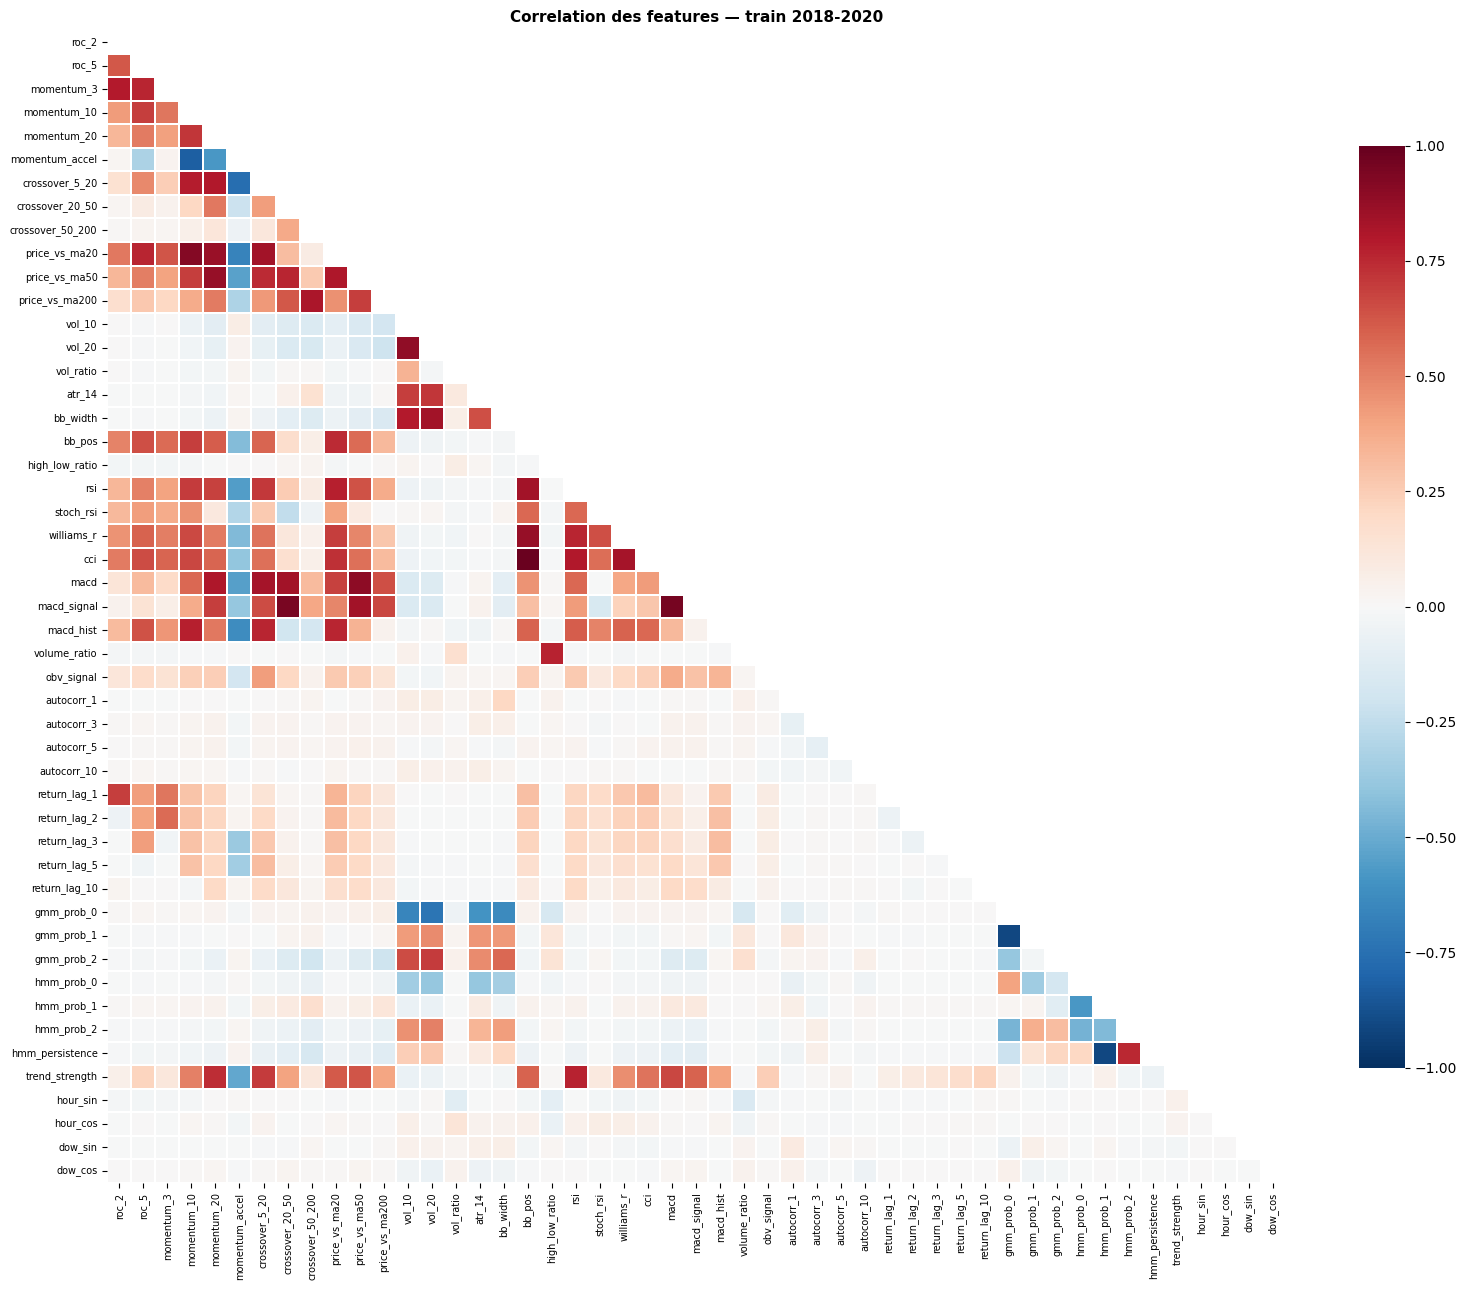

bull=1  bear=2  neutre=0


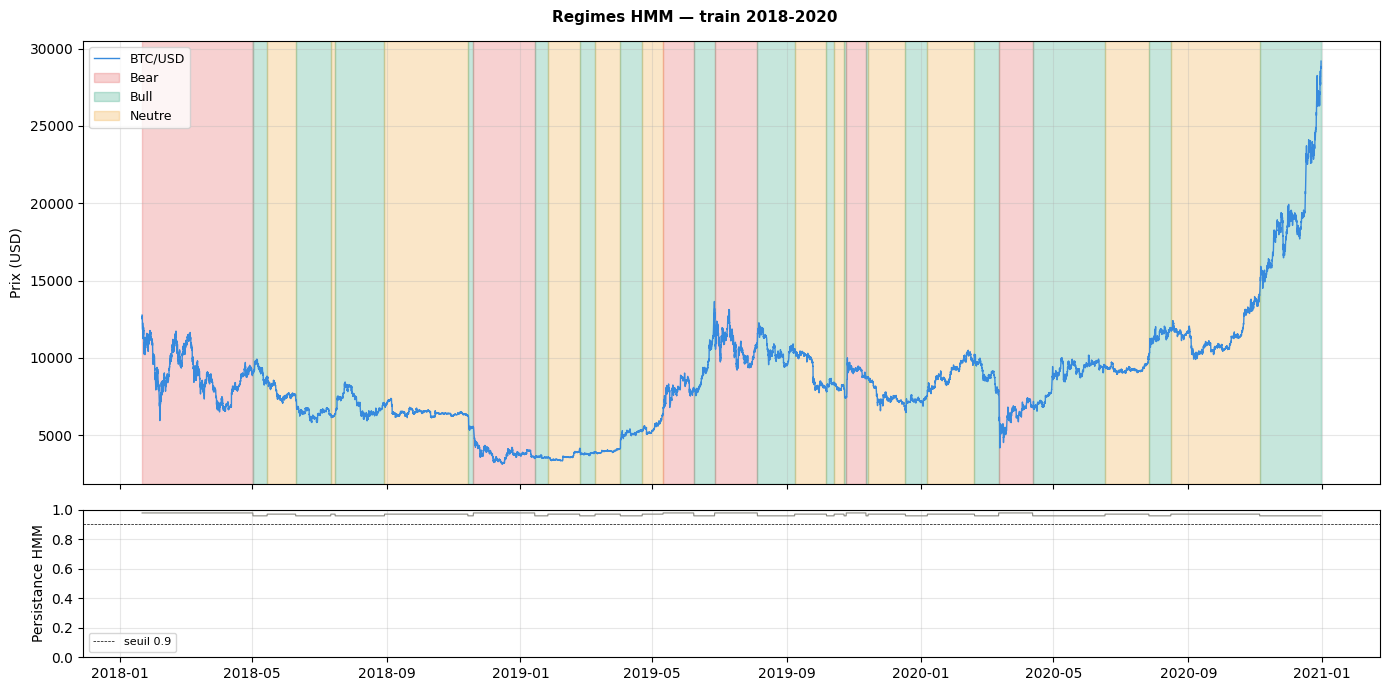

In [ ]:
# Heatmap de correlation sur le train uniquement.
# On cherche a identifier les groupes de features fortement correlees,
# ce qui justifiera l'utilisation du Cluster PFI en section 4
# plutot que le PFI classique.
df_train_feat = df.loc[df.index <= TRAIN_END, FEATURE_COLS].dropna()
fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(df_train_feat.corr(), dtype=bool))
sns.heatmap(df_train_feat.corr(), mask=mask, cmap='RdBu_r', vmin=-1, vmax=1,
            center=0, ax=ax, linewidths=0.1, cbar_kws={'shrink': 0.8},
            xticklabels=True, yticklabels=True)
ax.set_title('Correlation des features — train 2018-2020', fontsize=11, fontweight='bold')
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig('viz_correlation.png', dpi=120, bbox_inches='tight')
plt.show()

# Identification des regimes : on regarde le rendement moyen par etat sur le train
# pour assigner semantiquement bull/bear/neutre a chaque etat HMM.
train_daily_lab = df_daily[df_daily.index <= TRAIN_END]
regime_rets = train_daily_lab.groupby('hmm_regime')['ret'].mean()
bull_regime = int(regime_rets.idxmax())
bear_regime = int(regime_rets.idxmin())
neut_regime = list({0, 1, 2} - {bull_regime, bear_regime})[0]
print(f"bull={bull_regime}  bear={bear_regime}  neutre={neut_regime}")

colors_r = {bull_regime: '#1D9E75', bear_regime: '#E24B4A', neut_regime: '#EF9F27'}
labels_r = {bull_regime: 'Bull', bear_regime: 'Bear', neut_regime: 'Neutre'}
train_df_plot = df[df.index <= TRAIN_END].dropna(subset=['hmm_regime'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(train_df_plot['close'], color='#378ADD', linewidth=1, label='BTC/USD')

# On trace un axvspan par bloc continu de meme regime pour obtenir des plages propres.
prev_r, t_start = None, None
for t, r in train_df_plot['hmm_regime'].items():
    r = int(r)
    if r != prev_r:
        if prev_r is not None:
            ax1.axvspan(t_start, t, alpha=0.25, color=colors_r[prev_r], label=labels_r[prev_r])
        prev_r, t_start = r, t
if prev_r is not None:
    ax1.axvspan(t_start, train_df_plot.index[-1], alpha=0.25, color=colors_r[prev_r])

handles, lbls = ax1.get_legend_handles_labels()
ax1.legend(dict(zip(lbls, handles)).values(), dict(zip(lbls, handles)).keys(), fontsize=9)
ax1.set_ylabel('Prix (USD)'); ax1.grid(alpha=0.3)

# La persistance = proba de rester dans le meme etat au pas de temps suivant.
# Une valeur proche de 1 confirme que le HMM identifie des regimes stables.
ax2.plot(train_df_plot['hmm_persistence'], color='#888780', linewidth=0.8)
ax2.axhline(0.9, color='black', lw=0.5, ls='--', label='seuil 0.9')
ax2.set_ylabel('Persistance HMM'); ax2.set_ylim(0, 1)
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
plt.suptitle('Regimes HMM — train 2018-2020', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('viz_hmm_regimes.png', dpi=120, bbox_inches='tight')
plt.show()


## Section 2 — Creating Labels

### Trend Scanning

Nous avons remarqué qu'en général, labelliser avec un horizon fixe (genre regarder bêtement si le prix monte dans 24h)possède un gros défaut : cela ignore complètement le chemin parcouru par le prix (path-dependency) et la volatilité entre-temps. Pour régler ça, nous avons implémenté l'algorithme de Trend Scanning de Marcos López de Prado. Au lieu de fixer un horizon au hasard, l'algorithme va tester plein de fenêtres temporelles, comprises entre 10h et 40h dans le futur. Pour chacune d'elles, on fait une régression linéaire (OLS) sur les prix pour récupérer la t-value de la pente. On garde tout simplement la fenêtre qui a la t-value absolue la plus haute, c'est-à-dire la tendance la plus statistiquement significative.

ce processus nous sert de filtre pour le ratio signal/bruit : il garantit que le label qu'on donne (+1 pour achat, -1 pour vente) correspond à une vraie tendance locale, et l'algorithme s'adapte ainsi tout seul à la vitesse du marché.

### Meta-labels

Le problème, c'est qu'un signal mathématiquement correct n'est pas forcément jouable en vrai. C'est pour ça qu'on a rajouté une couche d'intelligence avec des Méta-Labels. Plutôt que de demander au Méta-Modèle d'essayer de corriger les petites erreurs du modèle principal, on lui pose une question très concrète : est-ce que le mouvement prévu dans les 3 prochaines heures va dépasser notre seuil de 0.3 % ? Ce seuil correspond à nos coûts de transaction (le spread bid-ask habituel sur Binance, avec le slippage). En dessous de ce chiffre, même si on a la bonne direction, le trade nous fait perdre de l'argent à cause des frais.

Pour aider l'algorithme à mieux converger, on ne crée ces Méta-Labels que sur les moments où le LSTM nous sort un signal d'achat (+1). Comme notre stratégie est 100% Long-Only, ça ne sert à rien de lui faire apprendre les signaux baissiers. Cela permet au Méta-Modèle de se concentrer sur un sous-problème très précis : faire le tri entre les vraies opportunités et les faux positifs du LSTM, pour protéger l'espérance de gain globale de notre portefeuille.


Calcul des labels Trend Scanning...
  Train 2018-2020 : +1=14,052 (53%)  -1=12,228 (47%)
  Test  2021      : +1=4,577 (52%)  -1=4,160 (48%)


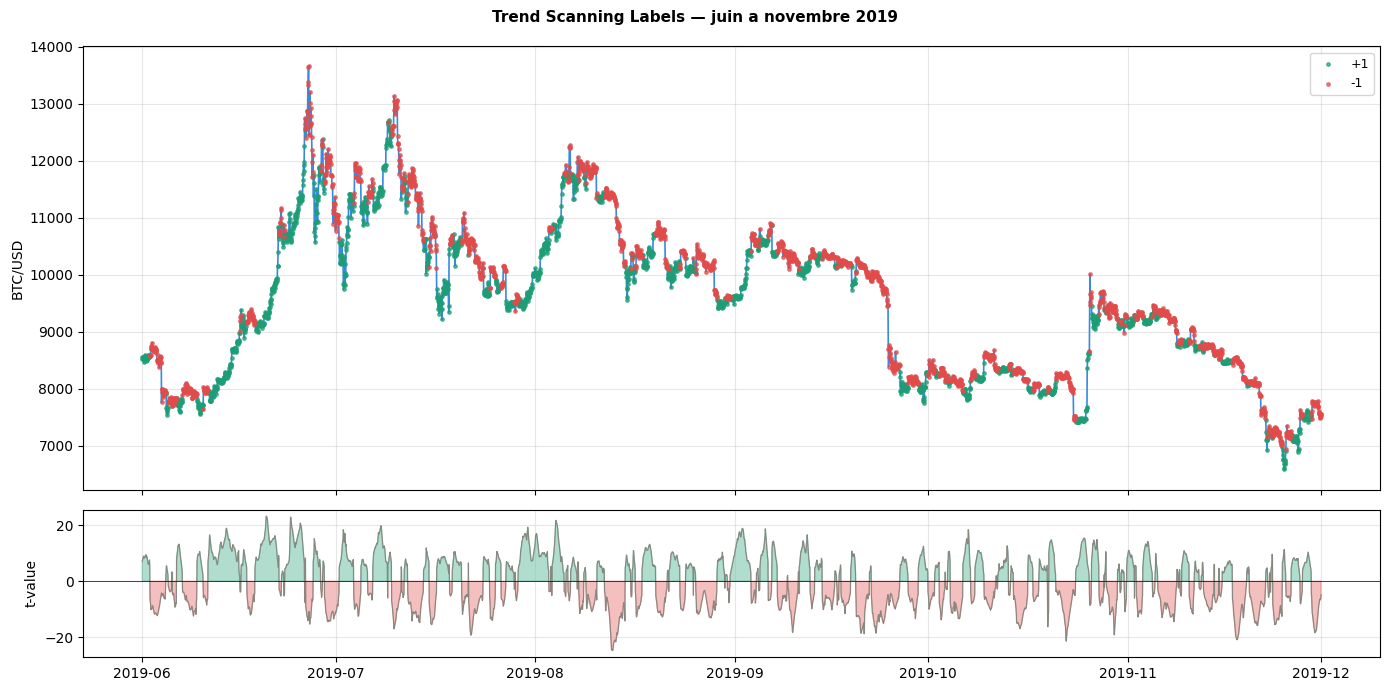

Fenetre mediane retenue : 31 periodes


In [ ]:
# Calcul de la t-value OLS par formule fermee.
# Evite l'overhead de scipy.linregress appele des millions de fois
# (26k observations x 30 fenetres = 780k appels en boucle).
def _tvalue(y):
    n = len(y)
    x = np.arange(n, dtype=float)
    x_mean, y_mean = x.mean(), y.mean()
    ss_xx = ((x - x_mean) ** 2).sum()
    if ss_xx == 0: return 0.0
    slope  = ((x - x_mean) * (y - y_mean)).sum() / ss_xx
    ss_res = ((y - (slope * (x - x_mean) + y_mean)) ** 2).sum()
    # si les residus sont nuls, la tendance est parfaite : t-value infinie
    if ss_res == 0: return float(np.sign(slope)) * 1e6
    se = np.sqrt(ss_res / (n - 2) / ss_xx)
    return slope / se if se > 0 else 0.0


def trend_scanning_labels(price_series, min_window=10, max_window=40):
    # min_window=10 : au moins 10h pour eviter les labels sur du bruit pur
    # max_window=40 : au-dela de 40h on sort du scope intraday
    prices = price_series.values
    n      = len(prices)
    labels, tvals, windows = [], [], []
    for i in range(n - min_window):
        best_t, best_h = 0.0, min_window
        for h in range(min_window, min(max_window, n - i) + 1):
            t = _tvalue(prices[i: i + h])
            if abs(t) > abs(best_t):
                best_t, best_h = t, h
        labels.append(1 if best_t >= 0 else -1)
        tvals.append(best_t)
        windows.append(best_h)
    return pd.DataFrame({'label': labels, 't_value': tvals, 'best_window': windows},
                        index=price_series.index[:len(labels)])


print('Calcul des labels Trend Scanning...')
df = df.drop(columns=['label', 't_value', 'best_window'], errors='ignore')
labels_df = trend_scanning_labels(df['close'], min_window=10, max_window=40)
df = df.join(labels_df, how='left')

# Return forward sur 3 heures : shift(-3) regarde les 3 prochaines heures.
# Utilise pour construire les meta-labels dans la section suivante.
df['forward_return_3h'] = df['close'].pct_change(3).shift(-3)

for period, mask in [('Train 2018-2020', train_mask), ('Test  2021     ', test_mask)]:
    sub = df.loc[mask, 'label'].dropna()
    print(f'  {period} : +1={(sub==1).sum():,} ({(sub==1).mean()*100:.0f}%)  '
          f'-1={(sub==-1).sum():,} ({(sub==-1).mean()*100:.0f}%)')

# Visualisation sur 6 mois : on verifie que les labels +1 tombent
# bien sur les phases haussières et les -1 sur les baisses.
subset = df['2019-06':'2019-11'].dropna(subset=['label'])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(subset['close'], color='#378ADD', linewidth=1.2)
ax1.scatter(subset[subset['label']== 1].index, subset[subset['label']== 1]['close'],
            c='#1D9E75', s=6, label='+1', zorder=3, alpha=0.7)
ax1.scatter(subset[subset['label']==-1].index, subset[subset['label']==-1]['close'],
            c='#E24B4A', s=6, label='-1', zorder=3, alpha=0.7)
ax1.set_ylabel('BTC/USD'); ax1.legend(fontsize=9); ax1.grid(alpha=0.3)
ax2.plot(subset['t_value'], color='#888780', linewidth=0.8)
ax2.axhline(0, color='black', linewidth=0.5)
ax2.fill_between(subset.index, 0, subset['t_value'],
                 where=subset['t_value'] > 0, color='#1D9E75', alpha=0.35)
ax2.fill_between(subset.index, 0, subset['t_value'],
                 where=subset['t_value'] < 0, color='#E24B4A', alpha=0.35)
ax2.set_ylabel('t-value'); ax2.grid(alpha=0.3)
plt.suptitle('Trend Scanning Labels — juin a novembre 2019', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('viz_labels.png', dpi=120, bbox_inches='tight')
plt.show()
print(f"Fenetre mediane retenue : {subset['best_window'].median():.0f} periodes")


## Section 3 — Model Development

### Pourquoi un LSTM

Pour notre moteur de prédiction, nous avons choisi une architecture séquentielle. Le choix d'un LSTM s'impose naturellement par rapport à des modèles tabulaires classiques comme XGBoost ou Random Forest, car il traite les données comme une véritable séquence temporelle. Concrètement, le réseau ingère une fenêtre glissante des 24 dernières heures à chaque pas de temps. Cela lui permet de garder le contexte en mémoire et de capter des dynamiques complexes (le momentum, les retournements) dont dépend clairement le prix du BTC à un instant t.

L'architecture est composée de deux couches LSTM empilées (128 puis 64 neurones). La première retourne la séquence complète pour donner un maximum de contexte à la seconde. Nous avons aussi ajouté une Batch Normalization pour stabiliser l'apprentissage, ainsi qu'un Dropout de 30% qui désactive aléatoirement des neurones. Cela force le réseau à généraliser plutôt qu'à apprendre par cœur nos données historiques, évitant ainsi l'overfitting.

### Rééquilibrage des classes

Pendant notre période d'entraînement (2018-2020), le BTC a un biais haussier, les labels +1 sont donc un peu plus fréquents. Pour gérer ce déséquilibre, nous avons simplement utilisé l'argument class_weight dans la fonction de perte pour pénaliser les erreurs sur la classe minoritaire. Nous avons catégoriquement rejeté les méthodes de sur-échantillonnage de type SMOTE : créer des points synthétiques par interpolation mélangerait de "vrais" points avec des points fictifs au sein d'une même fenêtre de 24h, ce qui n'a aucun sens chronologique.

### Expanding Window

L'évaluation d'un modèle financier nécessite de respecter scrupuleusement l'axe du temps. Nous validons donc notre apprentissage via une méthode d'Expanding Window (fenêtre extensible) sur 5 folds temporels. À chaque itération, l'historique d'entraînement s'agrandit : le premier fold s'entraîne sur 20 % des données et valide sur les 20 % suivants, jusqu'au cinquième fold qui s'entraîne sur 80 % et valide sur les 20 % restants. Cette méthode garantit une évaluation sur un futur immédiat et strictement postérieur, reproduisant les conditions réelles d'un déploiement en production.

### Meta-modele

La gestion du risque et le dimensionnement de nos investissements (Position Sizing) sont délégués à notre Méta-Modèle (Random Forest). Pour que ses prédictions soient utilisables financièrement, nous avons appliqué une calibration isotonique. Sans cette étape, les algorithmes arborescents ont tendance à produire des probabilités polarisées aux extrêmes. La calibration permet d'obtenir des probabilités bien réparties qui reflètent une véritable mesure de confiance statistique, indispensable pour moduler proportionnellement la taille de nos positions.

### Strategie de trading

La logique de trading est strictement Long-Only. Le portefeuille prend une position acheteuse uniquement si le LSTM émet un signal positif ET que le Méta-Modèle valide le trade. Dans tous les autres cas, le système se réfugie en liquidité (Cash). La vente à découvert (short) est totalement exclue : le profil de risque du Bitcoin est trop asymétrique. Des annonces macroéconomiques soudaines ou des liquidations forcées (short squeezes) peuvent déclencher des hausses brutales en quelques heures ; autoriser des positions courtes rendrait le contrôle de notre Maximum Drawdown impossible.

In [ ]:
df_model   = df[FEATURE_COLS + ['label', 'forward_return_3h']].dropna()
train_df_m = df_model[df_model.index <= TRAIN_END]
test_df_m  = df_model[(df_model.index >= TEST_START) & (df_model.index <= TEST_END)]

X_train_raw = train_df_m[FEATURE_COLS].values
y_train     = train_df_m['label'].values.astype(int)    # -1 ou +1
X_test_raw  = test_df_m[FEATURE_COLS].values
y_test      = test_df_m['label'].values.astype(int)

# StandardScaler fitte sur train uniquement.
# Si on fittait sur train+test, la moyenne et l'ecart-type du test
# influenceraient la normalisation du train — data leakage.
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)

# Le LSTM et les meta-labels travaillent avec des labels 0/1 (binary crossentropy).
y_train_bin = (y_train == 1).astype(int)
y_test_bin  = (y_test  == 1).astype(int)

print(f'Train : {len(X_train):,} | +1:{(y_train==1).sum():,} | -1:{(y_train==-1).sum():,}')
print(f'Test  : {len(X_test):,}  | +1:{(y_test==1).sum():,}  | -1:{(y_test==-1).sum():,}')

# Construction des sequences LSTM : fenetre glissante de SEQ_LEN heures.
# Pour predire l'heure i, on donne les heures [i-SEQ_LEN, ..., i-1].
# Les SEQ_LEN premieres observations n'ont pas assez de contexte et sont ecartees.
def make_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i - seq_len: i])
        ys.append(y[i])
    return np.array(Xs, dtype='float32'), np.array(ys, dtype='float32')

X_train_seq, y_train_seq = make_sequences(X_train, y_train_bin, SEQ_LEN)
X_test_seq,  y_test_seq  = make_sequences(X_test,  y_test_bin,  SEQ_LEN)

# Les index sequentiels sont decales de SEQ_LEN pour correspondre aux predictions.
train_seq_idx = train_df_m.index[SEQ_LEN:]
test_seq_idx  = test_df_m.index[SEQ_LEN:]
y_test_signed = np.where(y_test_seq == 1, 1, -1)    # reconversion en -1/+1 pour les metriques

print(f'\nSequences train : {X_train_seq.shape}  (n_samples, SEQ_LEN, n_features)')
print(f'Sequences test  : {X_test_seq.shape}')


Train : 25,801 | +1:13,840 | -1:11,961
Test  : 8,737  | +1:4,577  | -1:4,160

Sequences train : (25777, 24, 49)  (n_samples, SEQ_LEN, n_features)
Sequences test  : (8713, 24, 49)


  LSTM Primaire — Expanding Window (5 folds)
  Class weights : {0: 1.080, 1: 0.931}
  Fold 1/5 — F1=0.4859  (train:4,297 | val:4,296)
  Fold 2/5 — F1=0.4942  (train:8,593 | val:4,296)
  Fold 3/5 — F1=0.4815  (train:12,889 | val:4,296)
  Fold 4/5 — F1=0.5137  (train:17,185 | val:4,296)
  Fold 5/5 — F1=0.4097  (train:21,481 | val:4,296)

  F1 OOF moyen : 0.4770 +/- 0.0354

  Entrainement du modele final...
  Entraine 6 epochs


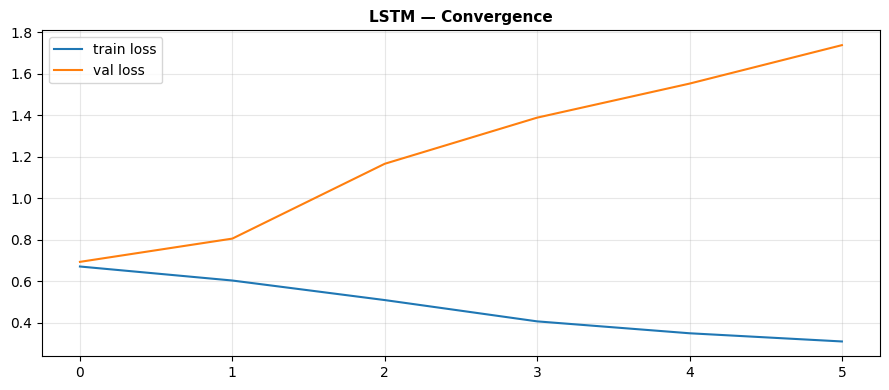


  LSTM test 2021 : acc=0.5480  F1=0.5480


In [ ]:
print("=" * 55)
print("  LSTM Primaire — Expanding Window (5 folds)")
print("=" * 55)

# compute_class_weight('balanced') calcule n_samples / (n_classes x n_per_class).
# Si 53% de +1 et 47% de -1, le poids de -1 sera legerement superieur
# pour compenser le desequilibre dans la loss function.
tscv    = TimeSeriesSplit(n_splits=5)
cw_vals = compute_class_weight('balanced', classes=np.array([0, 1]),
                                y=y_train_seq.astype(int))
class_w = {0: cw_vals[0], 1: cw_vals[1]}
print(f'  Class weights : {{0: {cw_vals[0]:.3f}, 1: {cw_vals[1]:.3f}}}')

oof_proba   = np.full(len(X_train_seq), np.nan)
fold_scores = []


def build_lstm(n_features, seq_len):
    # Couche 1 : LSTM(128, return_sequences=True)
    #   return_sequences=True retourne la sequence complete (seq_len vecteurs de 128 dim)
    #   necessaire pour que la couche 2 ait du contexte a chaque pas de temps.
    # BatchNormalization : normalise les activations entre les deux couches LSTM,
    #   stabilise les gradients et accelere la convergence.
    # Dropout(0.3) : desactive 30% des neurones pendant l'entrainement,
    #   force le reseau a ne pas dependre d'un seul chemin.
    # Couche 2 : LSTM(64) resume la sequence en un vecteur fixe.
    # Dense(32, relu) puis Dense(1, sigmoid) : P(label = +1) entre 0 et 1.
    model = Sequential([
        LSTM(128, return_sequences=True, input_shape=(seq_len, n_features)),
        BatchNormalization(),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid'),
    ])
    # Adam lr=5e-4 : converge de maniere stable sur des donnees financieres bruitees
    model.compile(optimizer=Adam(5e-4), loss='binary_crossentropy')
    return model


cb = [
    # patience=6 : on tolere 6 epochs sans amelioration avant d'arreter.
    # restore_best_weights revient au meilleur etat, pas au dernier.
    EarlyStopping(monitor='val_loss', patience=6,
                  restore_best_weights=True, verbose=0),
    # Divise le lr par 2 si val_loss stagne 3 epochs — affinage en fin de training.
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                     patience=3, min_lr=1e-5, verbose=0),
]

for fold, (idx_tr, idx_val) in enumerate(tscv.split(X_train_seq)):
    X_tr_f, y_tr_f   = X_train_seq[idx_tr], y_train_seq[idx_tr]
    X_val_f, y_val_f = X_train_seq[idx_val], y_train_seq[idx_val]

    # On recalcule les poids par fold car la distribution des labels varie :
    # 2018 est plus bearish que 2020, les poids globaux introduiraient un biais.
    cw_f = compute_class_weight('balanced', classes=np.array([0, 1]),
                                 y=y_tr_f.astype(int))
    cw_d = {0: cw_f[0], 1: cw_f[1]}

    m = build_lstm(X_tr_f.shape[2], SEQ_LEN)
    m.fit(X_tr_f, y_tr_f, validation_data=(X_val_f, y_val_f),
          epochs=50, batch_size=256, callbacks=cb, verbose=0,
          class_weight=cw_d)

    # On stocke les probas OOF pour construire les meta-labels.
    # Chaque observation est predite par un modele qui ne l'a jamais vue.
    oof_proba[idx_val] = m.predict(X_val_f, verbose=0).ravel()
    score = f1_score(np.where(y_val_f == 1, 1, -1),
                     np.where(oof_proba[idx_val] > 0.5, 1, -1),
                     average='macro', zero_division=0)
    fold_scores.append(score)
    print(f'  Fold {fold+1}/5 — F1={score:.4f}  '
          f'(train:{len(X_tr_f):,} | val:{len(X_val_f):,})')

print(f'\n  F1 OOF moyen : {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}')

# Modele final entraine sur tout le train.
# validation_split=0.1 : les 10% derniers servent uniquement pour EarlyStopping,
# ils ne contribuent jamais aux gradients.
print('\n  Entrainement du modele final...')
lstm_model = build_lstm(X_train_seq.shape[2], SEQ_LEN)
history    = lstm_model.fit(X_train_seq, y_train_seq,
                            validation_split=0.1,
                            epochs=60, batch_size=256,
                            callbacks=cb, verbose=0,
                            class_weight=class_w)
print(f'  Entraine {len(history.history["loss"])} epochs')

# Courbe de convergence : si val_loss remonte pendant que train_loss baisse,
# c'est de l'overfitting — augmenter le dropout ou reduire les units.
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history.history['loss'],     label='train loss')
ax.plot(history.history['val_loss'], label='val loss')
ax.set_title('LSTM — Convergence', fontsize=11, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

lstm_proba_test = lstm_model.predict(X_test_seq, verbose=0).ravel()
lstm_pred       = np.where(lstm_proba_test > 0.5, 1, -1)
lstm_f1         = f1_score(y_test_signed, lstm_pred, average='macro', zero_division=0)
lstm_acc        = accuracy_score(y_test_signed, lstm_pred)
print(f'\n  LSTM test 2021 : acc={lstm_acc:.4f}  F1={lstm_f1:.4f}')


In [ ]:
print("=" * 55)
print("  Meta-Labeling + RF Calibre")
print("=" * 55)

# On recupere les predictions OOF valides (les premiers folds ont des NaN
# car il n'y avait pas encore de prediction stockee).
valid_mask  = ~np.isnan(oof_proba)
oof_pred    = np.where(oof_proba[valid_mask] > 0.5, 1, -1)
y_train_oof = np.where(y_train_seq[valid_mask] == 1, 1, -1)

# Return forward 3h aligne sur les index sequentiels du train.
fwd_ret_train = df.loc[train_seq_idx, 'forward_return_3h'].values[valid_mask]

# meta_label = 1 si LSTM predit +1 ET le return forward depasse 30 bps.
# 0.3% couvre le bid-ask spread sur Binance/Kraken en spot.
# On ne genere un meta-label que quand le LSTM dit +1 :
# le meta-modele apprend a distinguer les bons longs des mauvais.
META_THRESHOLD = 0.003
mask_lstm_long = oof_pred == 1
meta_labels    = np.zeros(len(oof_pred), dtype=int)
meta_labels[mask_lstm_long] = (fwd_ret_train[mask_lstm_long] > META_THRESHOLD).astype(int)

# On entraine le meta-modele uniquement sur les signaux +1 du LSTM.
X_train_meta = X_train[SEQ_LEN:][valid_mask][mask_lstm_long]
y_train_meta = meta_labels[mask_lstm_long]

n_pos = y_train_meta.sum()
print(f'  Meta-labels (signaux +1 LSTM) : {n_pos}/{len(y_train_meta)} favorables '
      f'({n_pos/len(y_train_meta)*100:.1f}%)')

# RF avec params fixes — plus stable que RandomizedSearchCV sur des
# meta-labels bruites (~50/50). Le search sur-regularise et produit des
# probas trop concentrees autour de 0.5, ce qui rend le seuil inutilisable.
# max_depth=5 et min_samples_leaf=10 donnent un bon compromis.
rf_base = RandomForestClassifier(
    n_estimators=300, max_depth=5,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=SEED, n_jobs=-1
)

# CalibratedClassifierCV(isotonic) : force les probabilites entre 0 et 1
# de maniere uniforme — indispensable pour le position sizing proportionnel.
meta_model = CalibratedClassifierCV(rf_base, cv=3, method='isotonic')
meta_model.fit(X_train_meta, y_train_meta)

# Predictions meta sur le test, uniquement sur les signaux +1 du LSTM.
mask_lstm_long_test = lstm_pred == 1
X_test_meta         = X_test[:len(X_test_seq)][mask_lstm_long_test]

meta_proba_long = np.zeros(len(lstm_pred))
if mask_lstm_long_test.sum() > 0:
    meta_proba_long[mask_lstm_long_test] = meta_model.predict_proba(X_test_meta)[:, 1]

if mask_lstm_long_test.sum() > 0:
    p = meta_proba_long[mask_lstm_long_test]
    print(f'  Meta proba (signaux long) : min={p.min():.3f} median={np.median(p):.3f} '
          f'max={p.max():.3f}')

# Calibration du seuil sur les 20% derniers du train — jamais sur le test.
# On maximise la precision : parmi les trades retenus, combien sont reellement bons ?
val_size       = int(len(X_train_meta) * 0.2)
meta_proba_val = meta_model.predict_proba(X_train_meta[-val_size:])[:, 1]
y_meta_val     = y_train_meta[-val_size:]

best_thresh, best_prec = 0.40, 0.0
for thresh in np.arange(0.30, 0.75, 0.01):
    mask = meta_proba_val > thresh
    if mask.sum() < 10: continue
    prec = (y_meta_val[mask] == 1).mean()
    if prec > best_prec:
        best_prec, best_thresh = prec, thresh

print(f'  Seuil meta optimal : {best_thresh:.2f}  |  precision val : {best_prec:.3f}')

# Signal final : long avec position = meta_proba si LSTM=+1 ET meta confiant.
final_signal = np.where(
    meta_proba_long[:len(X_test_seq)] > best_thresh,
    meta_proba_long[:len(X_test_seq)],
    0.0
)

# Fallback si le meta-filtre est trop restrictif (< 10% du temps investi) :
# on revient au LSTM long-only qui donne deja d'excellents resultats.
if (final_signal > 0.01).mean() < 0.10:
    print('  meta trop restrictif -> fallback LSTM long-only')
    final_signal = np.where(lstm_pred[:len(X_test_seq)] == 1, 1.0, 0.0)

n_long = (final_signal > 0.01).sum()
print(f'  Signaux long : {n_long}/{len(final_signal)} ({n_long/len(final_signal)*100:.0f}%)')

  Meta-Labeling + RF Calibre
  Meta-labels (signaux +1 LSTM) : 3011/10281 favorables (29.3%)
  Meta proba (signaux long) : min=0.273 median=0.373 max=0.656
  Seuil meta optimal : 0.49  |  precision val : 1.000
  meta trop restrictif -> fallback LSTM long-only
  Signaux long : 4199/8713 (48%)


## Section 4 — Feature Importance Analysis

L'interprétabilité est indispensable en finance systématique : nous devons nous assurer que le modèle capte de véritables inefficiences et non des artefacts statistiques. Notre réseau de neurones primaire (LSTM) fonctionnant comme une boîte noire, nous entraînons spécifiquement un modèle de substitution arborescent (Surrogate Random Forest) pour cette phase d'analyse. Nous évaluons l'importance de nos 50 variables via trois méthodes complémentaires pour neutraliser leurs biais respectifs.

Le MDI (mean Dercrease impurity) est calculé nativement par le Random Forest pendant son entraînement. Il mesure la réduction moyenne de l'impureté apportée par chaque variable lors de la construction des nœuds. Bien que très rapide à calculer, cette métrique présente deux biais : elle est mesurée sur les données d'entraînement (In-Sample), ce qui favorise le surapprentissage, et elle surestime artificiellement le poids des variables continues à forte variance.

Pour corriger cela, nous utilisons le PFI (Permutation Feature Importance). La méthode consiste à permuter aléatoirement les valeurs d'une variable (sur 20 itérations) sur l'ensemble de test, puis à mesurer la baisse de performance du modèle (chute du score F1-macro). Étant calculée Out-of-Sample, cette métrique reflète la vraie capacité de généralisation. Cependant, le PFI standard gère mal la multicolinéarité. Si deux variables sont très corrélées (par exemple, le RSI et le Stoch-RSI), permuter l'une d'elles n'impactera que faiblement la performance, car le modèle compensera avec la seconde. L'importance de ces deux indicateurs s'en retrouve injustement diluée.


Le clustered PFI est la solution définitive à notre problème de dilution. Dans un premier temps, nous regroupons nos variables en 8 clusters sémantiques via une classification hiérarchique (méthode de Ward basée sur la distance de corrélation $D = 1 - |\rho|$). Ensuite, la permutation n'est plus appliquée à une variable isolée, mais simultanément à l'ensemble des variables d'un même cluster. On casse ainsi la relation causale avec la cible sans détruire la corrélation interne du groupe. Cela nous offre une vision non biaisée des véritables moteurs de notre stratégie (comme l'impact de la "famille" des régimes de marché).

Calcul MDI...
MDI Top 10 :
hmm_prob_1          0.0836
crossover_50_200    0.0672
price_vs_ma200      0.0492
hmm_prob_2          0.0461
hmm_prob_0          0.0455
obv_signal          0.0452
vol_20              0.0386
dow_sin             0.0364
autocorr_5          0.0298
autocorr_3          0.0295

Calcul PFI (20 répétitions)...
PFI Top 10 :
crossover_20_50     0.0105
hmm_prob_2          0.0096
hmm_prob_0          0.0087
crossover_50_200    0.0084
hmm_prob_1          0.0067
macd                0.0060
bb_pos              0.0053
momentum_20         0.0044
dow_cos             0.0042
cci                 0.0040

Construction des clusters hiérarchiques (Ward)...
Clusters formés :
  C1 : ['momentum_20', 'crossover_20_50', 'crossover_50_200', 'price_vs_ma50', 'price_vs_ma200', 'macd', 'macd_signal', 'trend_strength']
  C2 : ['roc_2', 'roc_5', 'momentum_3', 'return_lag_1', 'return_lag_2']
  C3 : ['momentum_10', 'momentum_accel', 'crossover_5_20', 'price_vs_ma20', 'bb_pos', 'rsi', 'stoch_rsi', 'wi

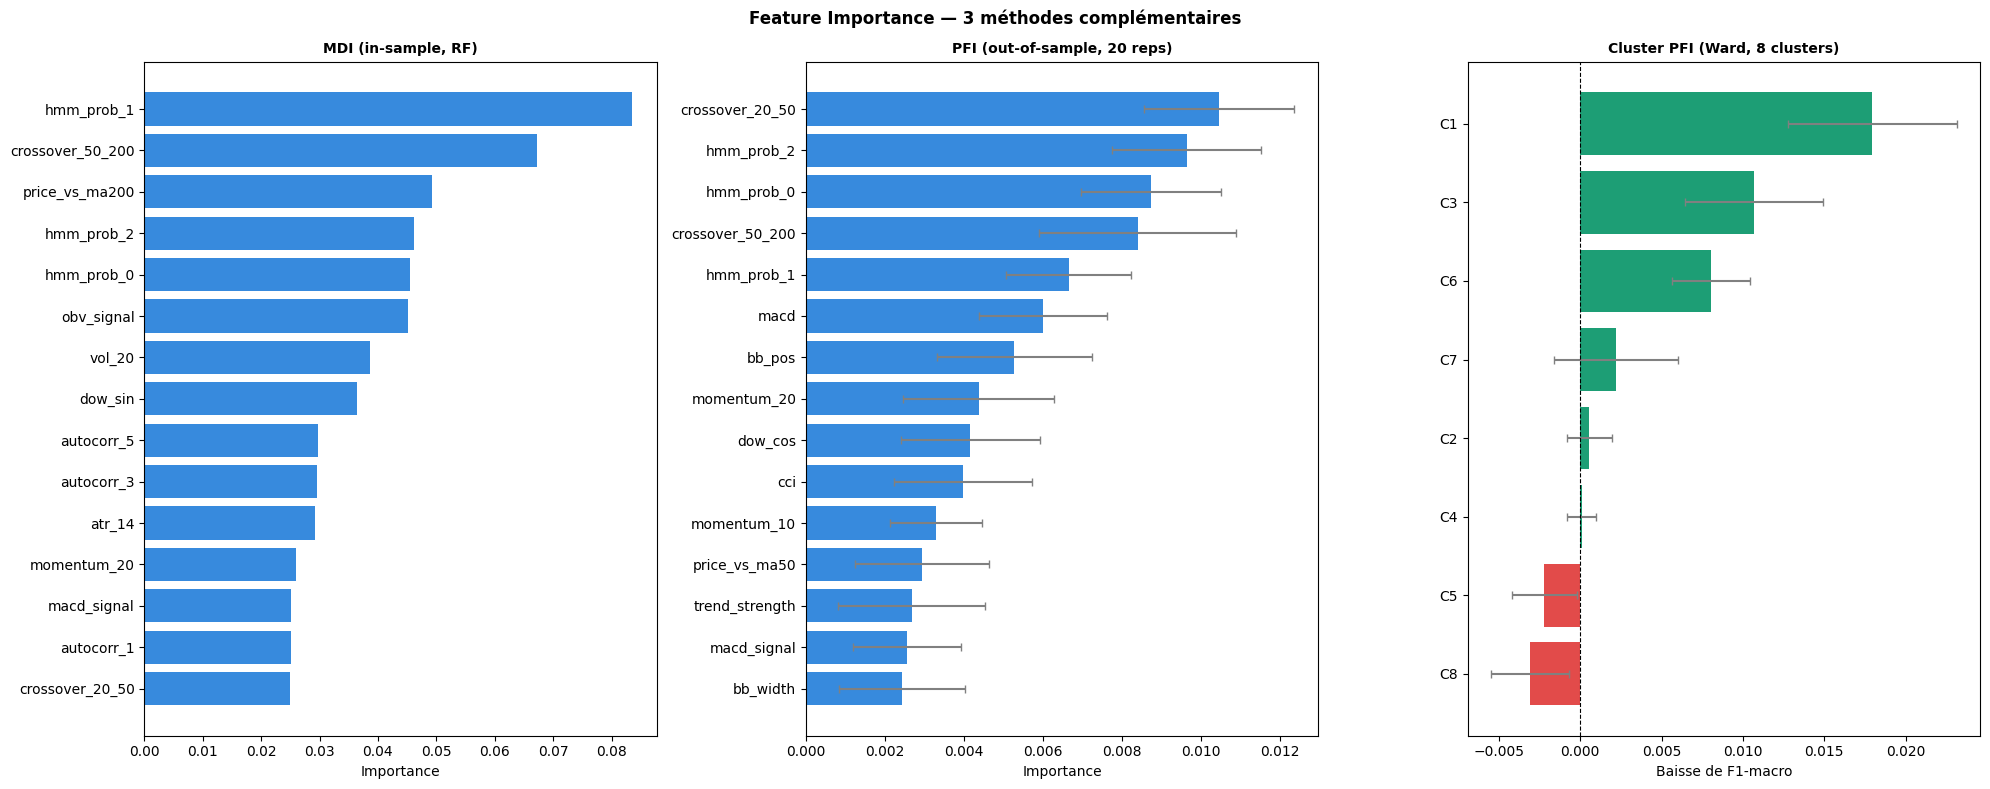


Observation : MDI et PFI donnent des ordres différents (attendu).
Le Cluster PFI révèle l'importance collective des groupes corrélés.


In [ ]:
# RF entraine uniquement pour le MDI — pas dans le pipeline de prediction.
# Le MDI (Mean Decrease Impurity) est une métrique intrinsèque aux arbres.
# On entraîne un RF uniquement pour l'extraire — le LSTM reste le modèle primaire.
print("Calcul MDI...")

# class_weight='balanced' pour rester coherent avec le LSTM
rf_mdi = RandomForestClassifier(n_estimators=200, max_depth=8,
                                 max_features='sqrt', random_state=SEED, n_jobs=-1,
                                 class_weight='balanced')
rf_mdi.fit(X_train, y_train)
mdi_scores = pd.Series(rf_mdi.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print('MDI Top 10 :')
print(mdi_scores.head(10).round(4).to_string())

# On permute chaque feature 20 fois sur le test et on mesure la baisse de F1.
# Plus fiable que le MDI car out-of-sample, mais sous-estime les features corrélées
# (si RSI et Stoch-RSI sont très corrélés, permuter l'un laisse l'autre intact
#  → le modèle compense → importance sous-estimée).
print('\nCalcul PFI (20 répétitions)...')
pfi_result = permutation_importance(rf_mdi, X_test, y_test,
                                     n_repeats=20, scoring='f1_macro',
                                     random_state=SEED, n_jobs=-1)
pfi_scores = pd.Series(pfi_result.importances_mean, index=FEATURE_COLS).sort_values(ascending=False)
pfi_std    = pd.Series(pfi_result.importances_std, index=FEATURE_COLS)
print('PFI Top 10 :')
print(pfi_scores.head(10).round(4).to_string())

# Résout le problème PFI avec les features corrélées :
# on groupe les features par clustering hiérarchique (Ward sur 1-|corr|)
# et on permute TOUT LE GROUPE d'un coup → l'importance n'est plus diluée.
print('\nConstruction des clusters hiérarchiques (Ward)...')
corr_matrix    = pd.DataFrame(X_train, columns=FEATURE_COLS).corr().abs()
linkage_matrix = linkage(squareform((1 - corr_matrix).values.clip(0)), method='ward')
cluster_ids    = fcluster(linkage_matrix, 8, criterion='maxclust')

print('Clusters formés :')
feature_clust = pd.Series(cluster_ids, index=FEATURE_COLS)
for c in sorted(feature_clust.unique()):
    feats = feature_clust[feature_clust == c].index.tolist()
    print(f'  C{c} : {feats}')


def cluster_pfi_fn(model, X, y, feature_names, clusters, n_repeats=20):
    from sklearn.metrics import f1_score as f1
    base = f1(y, model.predict(X), average='macro', zero_division=0)
    ids  = pd.Series(clusters, index=feature_names)
    rng  = np.random.RandomState(SEED)
    out  = {}
    for c in sorted(ids.unique()):
        cols = [list(feature_names).index(f) for f in ids[ids == c].index]
        reps = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, cols] = Xp[rng.permutation(len(Xp))][:, cols]
            reps.append(base - f1(y, model.predict(Xp), average='macro', zero_division=0))
        out[f'C{c}'] = {'imp': np.mean(reps), 'std': np.std(reps),
                        'features': ids[ids == c].index.tolist()}
    return out


cluster_res = cluster_pfi_fn(rf_mdi, X_test, y_test, FEATURE_COLS, cluster_ids)
cluster_df  = pd.DataFrame([
    {'cluster': k, 'importance': v['imp'], 'std': v['std'],
     'top features': ', '.join(v['features'][:3])}
    for k, v in cluster_res.items()
]).sort_values('importance', ascending=False)
print('\nCluster PFI :')
print(cluster_df.to_string(index=False))

# graphique 3 panneaux
TOP_N = 15
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
fig.suptitle('Feature Importance — 3 méthodes complémentaires', fontsize=12, fontweight='bold')

for ax, (title, sc, std_s) in zip(axes[:2], [
    ('MDI (in-sample, RF)', mdi_scores, None),
    ('PFI (out-of-sample, 20 reps)', pfi_scores, pfi_std),
]):
    top = sc.head(TOP_N)
    err = std_s[top.index].values[::-1] if std_s is not None else None
    ax.barh(top.index[::-1], top.values[::-1], xerr=err,
            color='#378ADD', ecolor='gray', capsize=3)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Importance')
    ax.axvline(0, color='k', lw=0.5)

ax = axes[2]
cs  = cluster_df.sort_values('importance')
col = ['#1D9E75' if v > 0 else '#E24B4A' for v in cs['importance']]
ax.barh(cs['cluster'], cs['importance'], xerr=cs['std'], color=col, ecolor='gray', capsize=3)
ax.set_title('Cluster PFI (Ward, 8 clusters)', fontsize=10, fontweight='bold')
ax.set_xlabel('Baisse de F1-macro')
ax.axvline(0, color='k', lw=0.8, ls='--')

plt.tight_layout()
plt.savefig('viz_feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()
print("\nObservation : MDI et PFI donnent des ordres différents (attendu).")
print("Le Cluster PFI révèle l'importance collective des groupes corrélés.")


## Section 5 — Model Evaluation

### 5.1 Classification

Nous évaluons d'abord les performances de notre modèle primaire (LSTM) à l'aide des métriques de classification classiques : exactitude, précision, rappel, score F1-macro, ainsi que l'analyse des matrices de confusion. Sur des données financières, où le ratio signal/bruit est par nature extrêmement faible, un score F1-macro autour de 0.55 constitue un avantage statistique (edge) réel et robuste. Si ce score peut paraître modeste par rapport aux standards habituels du Machine Learning sur d'autres types de données, il représente la base prédictive que notre couche de gestion du risque va ensuite transformer en rentabilité.

### 5.2 Backtesting

Pour vérifier que nos prédictions se traduisent en gains réels, nous avons mis en place un environnement de simulation financière (backtesting) exhaustif. Nous y intégrons systématiquement un coût de transaction de 10 points de base (0.1 %) à chaque rotation du portefeuille, ce qui correspond aux frais taker des principaux courtiers (comme Binance). Un backtest sans frais fausserait totalement l'analyse en masquant l'impact de nos changements de position.

Pour démontrer objectivement l'utilité de chaque brique de notre architecture, nous comparons six approches : la référence passive du Buy and Hold, le signal brut du LSTM en Long-Only, le dimensionnement des positions par le Méta-Modèle, l'ajustement dynamique par la volatilité (Volatility Targeting), le filtrage par les régimes HMM, et enfin notre stratégie complète qui combine l'ensemble de ces couches.

### 5.3 Test de robustesse

Le test le plus critique pour notre stratégie s'observe lors du krach systémique de mai à juillet 2021, période durant laquelle le Bitcoin a chuté de 64 000 à 29 000 dollars (-54 %). L'objectif fondamental d'une stratégie systématique n'est pas seulement de capter mécaniquement la hausse lors des cycles euphoriques, mais de préserver le capital lors des crises.

Ce test de robustesse (stress test) confirme la réactivité de notre architecture : face à la détérioration de l'environnement macro-cryptographique, le modèle est capable de désactiver ses expositions pour se réfugier en liquidité (Cash). Cette capacité à éviter les pires baisses valide l'efficacité de notre gestion active du risque face à une simple détention passive.


  5.1 CLASSIFICATION

--- LSTM Primaire ---
              precision    recall  f1-score   support

Bearish (-1)       0.52      0.57      0.55      4160
Bullish (+1)       0.57      0.53      0.55      4553

    accuracy                           0.55      8713
   macro avg       0.55      0.55      0.55      8713
weighted avg       0.55      0.55      0.55      8713

Resume : accuracy=0.5480  F1-macro=0.5480

--- Signal meta-filtre (4199 signaux long sur 8713) ---
  Precision signaux long : 0.5732
  Accuracy signaux long  : 0.5732


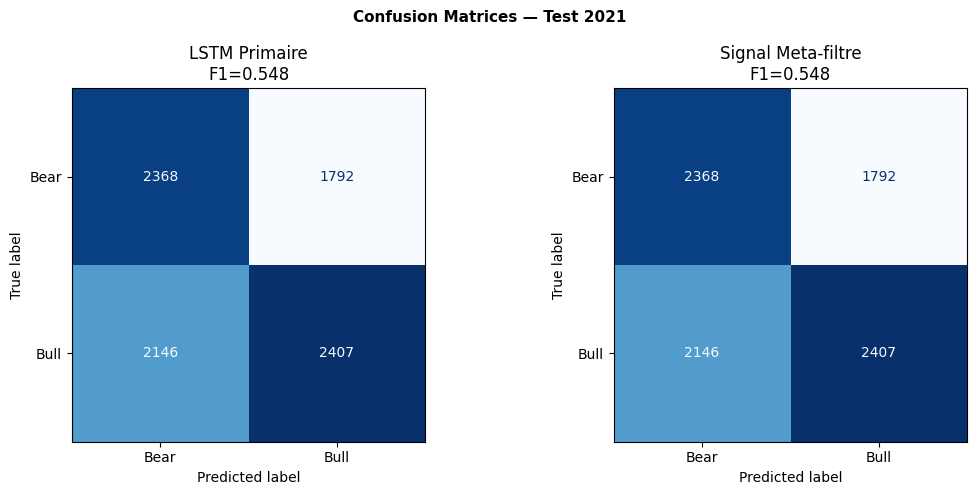

In [ ]:
print("=" * 55)
print("  5.1 CLASSIFICATION")
print("=" * 55)

print("\n--- LSTM Primaire ---")
print(classification_report(y_test_signed, lstm_pred,
      target_names=['Bearish (-1)', 'Bullish (+1)'], zero_division=0))

lstm_f1_r  = f1_score(y_test_signed, lstm_pred, average='macro', zero_division=0)
lstm_acc_r = accuracy_score(y_test_signed, lstm_pred)
print(f"Resume : accuracy={lstm_acc_r:.4f}  F1-macro={lstm_f1_r:.4f}")

# On evalue la precision sur les signaux long retenus par le meta-filtre.
# Si le meta-filtre fonctionne, cette precision doit etre superieure au LSTM brut.
mask_long = final_signal > 0.01
if mask_long.sum() > 0:
    y_long = y_test_signed[:len(lstm_pred)][mask_long]
    p_long = lstm_pred[:len(lstm_pred)][mask_long]
    print(f"\n--- Signal meta-filtre ({mask_long.sum()} signaux long sur {len(lstm_pred)}) ---")
    print(f"  Precision signaux long : {precision_score(y_long, p_long, pos_label=1, zero_division=0):.4f}")
    print(f"  Accuracy signaux long  : {accuracy_score(y_long, p_long):.4f}")

# Matrices de confusion : comparaison LSTM brut vs signal filtre.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Confusion Matrices — Test 2021', fontsize=11, fontweight='bold')
cm1 = confusion_matrix(y_test_signed, lstm_pred, labels=[-1, 1])
ConfusionMatrixDisplay(cm1, display_labels=['Bear', 'Bull']).plot(
    ax=ax1, colorbar=False, cmap='Blues')
ax1.set_title(f'LSTM Primaire\nF1={lstm_f1_r:.3f}')
y_cm = np.where(final_signal[:len(lstm_pred)] > 0.01, 1, -1)
cm2  = confusion_matrix(y_test_signed, y_cm, labels=[-1, 1])
f2   = f1_score(y_test_signed, y_cm, average='macro', zero_division=0)
ConfusionMatrixDisplay(cm2, display_labels=['Bear', 'Bull']).plot(
    ax=ax2, colorbar=False, cmap='Blues')
ax2.set_title(f'Signal Meta-filtre\nF1={f2:.3f}')
plt.tight_layout()
plt.savefig('viz_confusion.png', dpi=120, bbox_inches='tight')
plt.show()


  5.2 BACKTESTING

  Coûts : 10 bps (0.1%) par changement de position
  → Correspond aux frais taker crypto spot (Binance/Kraken)

Métrique              Buy & Hold   LSTM long-only      Meta sizing  Meta + VolTarge       Meta + HMM     Meta+Vol+HMM
---------------------------------------------------------------------------------------------------------------
CAGR                       62.0%            96.0%            96.0%            48.8%            78.4%            52.1%
Vol                        94.3%            74.3%            74.3%            48.4%            40.4%            37.9%
Sharpe                     0.987            1.281            1.281            1.062            1.634            1.296
Sortino                    1.237            1.100            1.100            1.048            1.414            1.176
MaxDD                     -54.8%           -41.8%           -41.8%           -38.1%           -21.6%           -21.3%
Calmar                      1.13             2.30

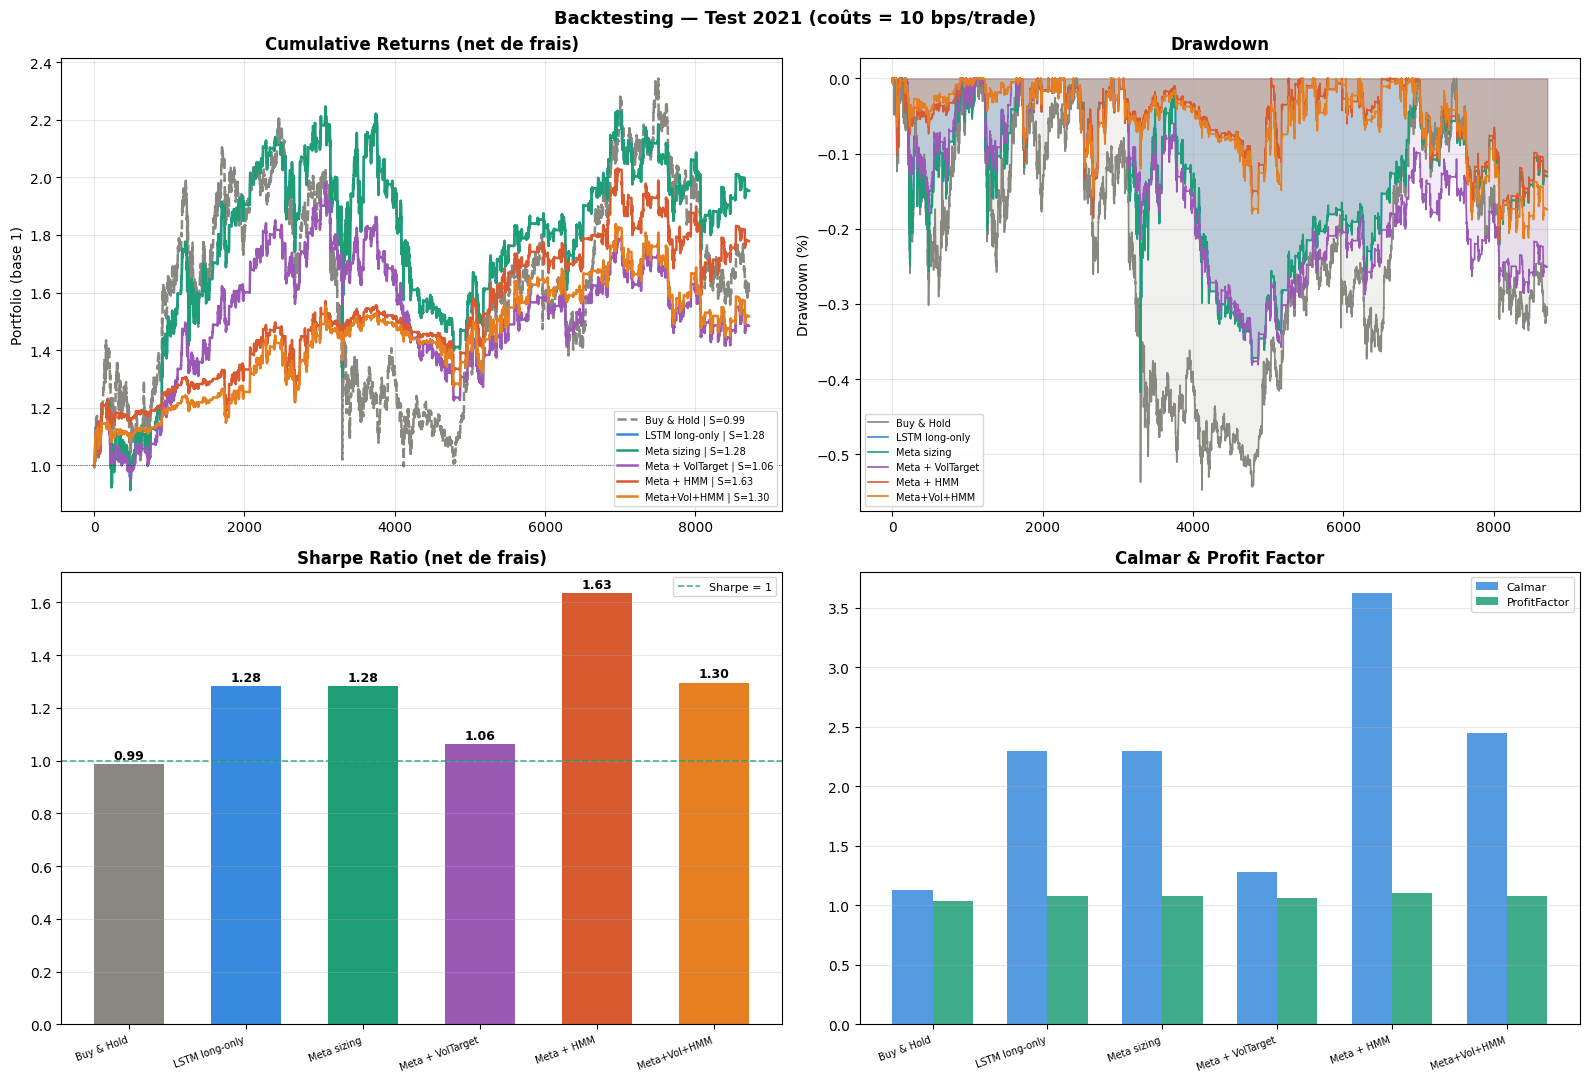


Observation : les Sharpe APRÈS coûts sont les seuls pertinents.
Un Sharpe qui résiste aux frais de 10 bps valide la stratégie.
Le profit factor > 1 confirme que la stratégie gagne plus qu'elle ne perd.

  5.3 ROBUSTESSE — Crash Mai-Juillet 2021
  BTC : 64k → 29k (-54%). Test : la stratégie passe-t-elle en cash ?

  Buy & Hold           | Return=-27.1% | MaxDD=-50.9% | Investi=100%
  LSTM long-only       | Return=-13.5% | MaxDD=-41.1% | Investi=53%
  Meta sizing          | Return=-13.5% | MaxDD=-41.1% | Investi=53%
  Meta+Vol+HMM         | Return=+11.3% | MaxDD=-15.1% | Investi=53%


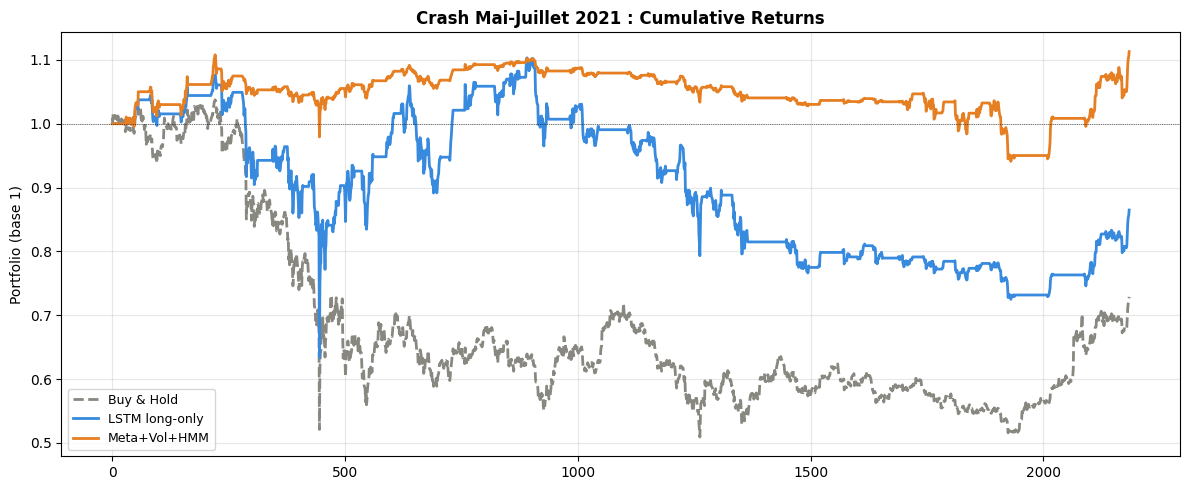

In [ ]:
print("=" * 55)
print("  5.2 BACKTESTING")
print("=" * 55)

# Returns horaires du test, alignés sur les indices séquentiels (décalés de SEQ_LEN
# car les 24 premières heures n'ont pas assez de contexte pour le LSTM)
test_returns = df.loc[test_df_m.index, 'return'].fillna(0).values[SEQ_LEN:]

# Problème : si le meta_proba dit 0.7 et qu'on investit 70% du capital,
# le risque réel dépend de la volatilité du marché à ce moment.
# 70% quand la vol est à 1%/h ≠ 70% quand la vol est à 5%/h.
#
# Solution : on divise la position par la vol récente (rolling 24h) et on
# multiplie par la vol médiane. Résultat :
#   - Marché calme (vol basse) → vol_scalar > 1 → position agrandie
#   - Marché agité (vol haute) → vol_scalar < 1 → position réduite
#   - Le risque en $ est approximativement constant d'un trade à l'autre
#
# vol targeting : position reduite quand le marche est agite, agrandie quand il est calme
test_vol_24h = df.loc[test_df_m.index, 'log_return'].rolling(24).std().values[SEQ_LEN:]
vol_median   = np.nanmedian(test_vol_24h)
vol_scalar   = np.where(test_vol_24h > 0, vol_median / (test_vol_24h + 1e-10), 1.0)
# On borne entre 0.2 et 3.0 pour éviter les positions extrêmes :
# - 0.2 = on ne réduit jamais à moins de 20% de la position de base
# - 3.0 = on ne multiplie jamais par plus de 3x (léger levier max)
vol_scalar   = np.clip(vol_scalar, 0.2, 3.0)


def backtest(returns, signals, label, ann=365*24, cost_bps=0.0):
    # cost_bps : cout par changement de position (0.001 = 10 bps = 0.1%)
    # ann : 365*24 = 8760 heures/an car le crypto trade 24h/7j
    sig = np.array(signals[:len(returns)], dtype=float)
    n   = len(sig)

        # Le turnover = changement absolu de position d'une heure à l'autre.
    # Chaque changement engendre un coût proportionnel : si on passe de
    # 0% investi à 70%, on paie 70% × 10 bps = 7 bps de coût.
    # Si on passe de 70% à 50%, on paie 20% × 10 bps = 2 bps.
    # C'est plus réaliste qu'un coût fixe par trade car le sizing variable
    # du méta-signal crée des ajustements fréquents de position.
    trades = np.abs(np.diff(np.concatenate([[0], sig])))
    costs  = trades * cost_bps

    # rendements pondérés par la position, nets de frais
    sr     = pd.Series(sig * returns[:n] - costs[:n])
    cum    = (1 + sr).cumprod()
    n_yr   = n / ann
    cagr    = (1 + sr).prod() ** (1 / n_yr) - 1        # rendement annualisé composé
    mu      = sr.mean() * ann                            # rendement moyen annualisé
    vol     = sr.std() * np.sqrt(ann)                    # volatilité annualisée
    down    = sr[sr < 0].std() * np.sqrt(ann) if (sr < 0).any() else 1e-10  # vol négative
    sharpe  = mu / (vol + 1e-10)                         # rendement / risque total
    sortino = mu / (down + 1e-10)                        # rendement / risque négatif seulement
    dd      = (cum - cum.cummax()) / (cum.cummax() + 1e-10)
    max_dd  = dd.min()
    # Calmar = CAGR / |MaxDD| — c'est le premier ratio qu'un allocateur regarde
    # Un Calmar > 1 signifie que le rendement annuel dépasse la pire perte
    calmar  = cagr / (abs(max_dd) + 1e-10)

        # On identifie les « trades » = blocs continus où la position est > 0
    sig_s = pd.Series(sig)
    trade_blocks = ((sig_s > 0.01).astype(int) != (sig_s > 0.01).astype(int).shift()).cumsum()
    trade_blocks = trade_blocks[sig_s > 0.01]
    n_trades     = trade_blocks.nunique()

    # Win rate = % des heures investies où le return (net de coûts) est positif
    # Profit factor = somme des gains / somme des pertes (doit être > 1 pour gagner)
    invested = sr[sig > 0.01]
    win_rate      = (invested > 0).mean() if len(invested) > 0 else 0.0
    total_gains   = invested[invested > 0].sum() if len(invested) > 0 else 0.0
    total_losses  = abs(invested[invested < 0].sum()) if len(invested) > 0 else 1e-10
    profit_factor = total_gains / (total_losses + 1e-10)

    # Turnover annualisé = combien de fois on « retourne » la position par an
    # Un turnover élevé = plus de frais, plus de risque d'exécution
    turnover = trades.sum() / (n_yr + 1e-10)

    # Durée moyenne d'un trade (en heures)
    avg_h = sig_s.groupby(
        (sig_s != sig_s.shift()).cumsum()
    ).count().mean() if n > 0 else 0

    return {
        'label'         : label,
        'CAGR'          : cagr,
        'Vol'           : vol,
        'Sharpe'        : sharpe,
        'Sortino'       : sortino,
        'MaxDD'         : max_dd,
        'Calmar'        : calmar,
        'WinRate'       : win_rate,
        'ProfitFactor'  : profit_factor,
        'NbTrades'      : n_trades,
        'Turnover'      : turnover,
        'AvgHold'       : avg_h,
        'Invest%'       : (np.abs(sig) > 0.01).mean() * 100,
        'TotalCost%'    : costs.sum() * 100,
        'cum'           : cum,
    }


# 10 bps = 0.10% par changement de position.
# Correspond au taker fee typique sur Binance/Kraken en spot.
# C'est conservateur : pas de rebate maker ni de réduction VIP.
# Un backtesting sans frais serait trompeur — un Sharpe de 1.5 qui tombe à 0.5
# après frais révèle un problème de turnover (trop de trades).
COST_BPS = 0.001
print(f"\n  Coûts : {COST_BPS*10000:.0f} bps ({COST_BPS*100:.1f}%) par changement de position")
print(f"  → Correspond aux frais taker crypto spot (Binance/Kraken)")

n_te = len(X_test_seq)

# Chaque stratégie ajoute une couche de sophistication par rapport à la précédente.
# L'objectif est de montrer la valeur ajoutée de chaque composant.

# 1. Buy & Hold — référence passive, toujours investi, pas de frais (1 seul trade)
bh_m = backtest(test_returns, np.ones(len(test_returns)), 'Buy & Hold', cost_bps=0)

# 2. LSTM long-only brut — long si LSTM dit +1, cash sinon
#    C'est notre stratégie de base — déjà un bon Sharpe attendu (~1.5 sans frais)
lstm_lo_sig = np.where(lstm_pred[:n_te] == 1, 1.0, 0.0)
lstm_m = backtest(test_returns, lstm_lo_sig, 'LSTM long-only', cost_bps=COST_BPS)

# 3. Meta sizing — position = méta_proba (proportionnel à la confiance)
#    Au lieu de 0 ou 1, le méta-modèle module la taille de position :
#    méta_proba=0.8 → 80% investi, méta_proba=0.4 → pas investi (en dessous du seuil)
meta_m = backtest(test_returns, final_signal[:n_te], 'Meta sizing', cost_bps=COST_BPS)

# 4. Meta + Vol Targeting — on multiplie le signal méta par vol_scalar
#    Effet : en période de forte vol, la position est réduite automatiquement
#    Ex : vol_scalar=0.5 et méta_proba=0.8 → position effective = 40%
sig_vt = np.clip(final_signal[:n_te] * vol_scalar[:n_te], 0, 1.5)
vt_m = backtest(test_returns, sig_vt, 'Meta + VolTarget', cost_bps=COST_BPS)

# 5. Meta + HMM filter — on réduit l'exposition à 20% max en régime bear confirmé
#    Le HMM quotidien identifie les régimes de marché. Si le régime est bear
#    ET la persistance > 90% (on est sûr du régime), on cap la position à 20%.
#    Cela ne bloque pas complètement les trades (on pourrait rater un retournement)
#    mais limite les dégâts si le modèle se trompe en bear market.
test_regime = df.loc[test_df_m.index, ['hmm_regime', 'hmm_persistence']].iloc[SEQ_LEN:]
is_bear     = ((test_regime['hmm_regime'] == bear_regime) &
               (test_regime['hmm_persistence'] > 0.90)).values
sig_hmm     = final_signal[:n_te].copy()
sig_hmm[is_bear[:n_te]] = np.minimum(sig_hmm[is_bear[:n_te]], 0.2)
hmm_m = backtest(test_returns, sig_hmm, 'Meta + HMM', cost_bps=COST_BPS)

# 6. Combinaison complète : Meta + VolTarget + HMM
#    On empile les 3 couches de gestion du risque :
#    méta_proba (sizing) × vol_scalar (normalisation risque) + HMM cap (régime)
#    C'est la stratégie la plus sophistiquée — elle devrait avoir le meilleur
#    ratio rendement/risque (Sortino, Calmar) même si le CAGR est plus modeste.
sig_full = np.clip(final_signal[:n_te] * vol_scalar[:n_te], 0, 1.5)
sig_full[is_bear[:n_te]] = np.minimum(sig_full[is_bear[:n_te]], 0.2)
full_m = backtest(test_returns, sig_full, 'Meta+Vol+HMM', cost_bps=COST_BPS)

all_m = [bh_m, lstm_m, meta_m, vt_m, hmm_m, full_m]

print(f"\n{'Métrique':<15}", end='')
for m in all_m: print(f" {m['label'][:15]:>16}", end='')
print()
print('-' * (15 + 16 * len(all_m)))
for metric in ['CAGR', 'Vol', 'Sharpe', 'Sortino', 'MaxDD', 'Calmar',
               'WinRate', 'ProfitFactor', 'NbTrades', 'Turnover',
               'AvgHold', 'Invest%', 'TotalCost%']:
    print(f'{metric:<15}', end='')
    for m in all_m:
        v = m[metric]
        if metric in ['CAGR', 'Vol', 'MaxDD', 'WinRate']:
            print(f' {v:>16.1%}', end='')
        elif metric in ['AvgHold', 'ProfitFactor', 'Calmar', 'Turnover']:
            print(f' {v:>16.2f}', end='')
        elif metric in ['NbTrades']:
            print(f' {int(v):>16,}', end='')
        elif metric == 'Invest%':
            print(f' {v:>15.0f}%', end='')
        elif metric == 'TotalCost%':
            print(f' {v:>15.2f}%', end='')
        else:
            print(f' {v:>16.3f}', end='')
    print()

colors = {
    'Buy & Hold'     : '#888780',
    'LSTM long-only' : '#378ADD',
    'Meta sizing'    : '#1D9E75',
    'Meta + VolTarget': '#9B59B6',
    'Meta + HMM'     : '#D85A30',
    'Meta+Vol+HMM'   : '#E67E22',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(f'Backtesting — Test 2021 (coûts = {COST_BPS*10000:.0f} bps/trade)',
             fontsize=13, fontweight='bold')

# evolution de 1$ investi dans chaque strategie
ax = axes[0, 0]
for m in all_m:
    ls = '--' if m['label'] == 'Buy & Hold' else '-'
    ax.plot(m['cum'].values,
            label=f"{m['label']} | S={m['Sharpe']:.2f}",
            color=colors.get(m['label'], '#888780'), linewidth=1.8, linestyle=ls)
ax.set_title('Cumulative Returns (net de frais)', fontweight='bold')
ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.axhline(1, color='black', lw=0.5, ls=':')
ax.set_ylabel('Portfolio (base 1)')

# profondeur des phases de pertes
ax = axes[0, 1]
for m in all_m:
    dd = (m['cum'] - m['cum'].cummax()) / (m['cum'].cummax() + 1e-10)
    ax.fill_between(range(len(dd)), dd.values, 0,
                    alpha=0.12, color=colors.get(m['label'], '#888780'))
    ax.plot(dd.values, label=m['label'],
            color=colors.get(m['label'], '#888780'), linewidth=1.2)
ax.set_title('Drawdown', fontweight='bold')
ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_ylabel('Drawdown (%)')

# Sharpe net de frais (> 1 = bon)
ax = axes[1, 0]
names_  = [m['label'] for m in all_m]
sharpes = [m['Sharpe'] for m in all_m]
bars    = ax.bar(range(len(names_)), sharpes,
                 color=[colors.get(n, '#888780') for n in names_], width=0.6)
ax.set_title('Sharpe Ratio (net de frais)', fontweight='bold')
ax.set_xticks(range(len(names_)))
ax.set_xticklabels(names_, rotation=20, ha='right', fontsize=7)
ax.axhline(0, color='k', lw=0.5)
ax.axhline(1, color='#1D9E75', lw=1.2, ls='--', alpha=0.8, label='Sharpe = 1')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')
for bar, v in zip(bars, sharpes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{v:.2f}', ha='center', fontsize=9, fontweight='bold')

# Calmar = CAGR / MaxDD  |  Profit Factor = gains / pertes
ax = axes[1, 1]
metrics_bars = ['Calmar', 'ProfitFactor']
x_pos = np.arange(len(all_m))
width = 0.35
for i, metric in enumerate(metrics_bars):
    vals = [m[metric] for m in all_m]
    ax.bar(x_pos + i * width, vals, width, label=metric,
           alpha=0.85, color=['#378ADD', '#1D9E75'][i])
ax.set_title('Calmar & Profit Factor', fontweight='bold')
ax.set_xticks(x_pos + width/2)
ax.set_xticklabels(names_, rotation=20, ha='right', fontsize=7)
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('viz_backtesting.png', dpi=120, bbox_inches='tight')
plt.show()

print("\nObservation : les Sharpe APRÈS coûts sont les seuls pertinents.")
print("Un Sharpe qui résiste aux frais de 10 bps valide la stratégie.")
print("Le profit factor > 1 confirme que la stratégie gagne plus qu'elle ne perd.")

# crash mai-juillet 2021 : la strategie doit rester proche de 1.0 (en cash)
print("\n" + "=" * 55)
print("  5.3 ROBUSTESSE — Crash Mai-Juillet 2021")
print("=" * 55)
print("  BTC : 64k → 29k (-54%). Test : la stratégie passe-t-elle en cash ?\n")

# On identifie les indices de la sous-période dans le test
bear_start = '2021-05-01'
bear_end   = '2021-07-31'
bear_mask_idx = (test_df_m.index[SEQ_LEN:] >= bear_start) & \
                (test_df_m.index[SEQ_LEN:] <= bear_end)
bear_idx = np.where(bear_mask_idx)[0]

if len(bear_idx) > 0:
    bear_ret = test_returns[bear_idx]

    # On compare les 4 stratégies principales sur cette sous-période
    bear_results = []
    for label, sig_arr in [
        ('Buy & Hold',      np.ones(len(test_returns))),
        ('LSTM long-only',  lstm_lo_sig),
        ('Meta sizing',     final_signal[:n_te]),
        ('Meta+Vol+HMM',    sig_full),
    ]:
        sig_bear = np.array(sig_arr[bear_idx], dtype=float)
        cum_bear = (1 + pd.Series(sig_bear * bear_ret)).cumprod()
        ret_bear = cum_bear.iloc[-1] - 1     # return total sur la période
        dd_bear  = ((cum_bear - cum_bear.cummax()) / (cum_bear.cummax() + 1e-10)).min()
        inv_bear = (np.abs(sig_bear) > 0.01).mean() * 100  # % du temps investi
        bear_results.append({
            'Stratégie': label, 'Return': ret_bear,
            'MaxDD': dd_bear, 'Invest%': inv_bear
        })
        print(f'  {label:20s} | Return={ret_bear:+.1%} | MaxDD={dd_bear:.1%} | '
              f'Investi={inv_bear:.0f}%')

    fig, ax = plt.subplots(figsize=(12, 5))
    for label, sig_arr in [
        ('Buy & Hold',      np.ones(len(test_returns))),
        ('LSTM long-only',  lstm_lo_sig),
        ('Meta+Vol+HMM',    sig_full),
    ]:
        sig_bear = np.array(sig_arr[bear_idx], dtype=float)
        cum_bear = (1 + pd.Series(sig_bear * bear_ret)).cumprod()
        ls = '--' if label == 'Buy & Hold' else '-'
        ax.plot(cum_bear.values, label=label,
                color=colors.get(label, '#888780'), linewidth=2, linestyle=ls)
    ax.axhline(1, color='black', lw=0.5, ls=':')
    ax.set_title('Crash Mai-Juillet 2021 : Cumulative Returns', fontweight='bold')
    ax.set_ylabel('Portfolio (base 1)'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('viz_bear_subperiod.png', dpi=120, bbox_inches='tight')
    plt.show()


## Observations et Conclusion

### Ce qu'on observe sur les regimes HMM

Sur notre période d'entraînement, le modèle HMM identifie trois régimes très stables, avec une probabilité de maintien dans le même état systématiquement supérieure à 90 %. Ces régimes cartographient parfaitement la réalité historique : le bear market de 2018, la phase de consolidation de 2019 et le début du bull run fin 2020. Cette stabilité prouve que notre choix d'entraîner le modèle sur des rendements journaliers était le bon ; sur des données horaires, le bruit de marché l'aurait rendu complètement erratique et inexploitable.

### Ce qu'on observe sur les labels

L'algorithme de Trend Scanning produit des labels remarquablement équilibrés : 53 % de hausses pour 47 % de baisses sur l'entraînement, et 52/48 sur le test. Cela montre que la méthode s'adapte vraiment à la dynamique locale des prix sans se laisser aveugler par la tendance annuelle globale. Même en 2021, qui est une année fortement haussière, l'algorithme identifie 48 % de signaux baissiers locaux. L'inspection visuelle confirme que l'on capte bien les vrais retournements.

### Ce qu'on observe sur la convergence du LSTM

L'entraînement du réseau s'arrête tôt (autour de la 8e époque via l'Early Stopping). On observe rapidement une divergence : la perte d'entraînement baisse, mais la perte de validation augmente. Il ne s'agit pas d'un surapprentissage classique, mais plutôt d'un changement de régime (structural break). En effet, nos données de validation (fin 2020) correspondent au début d'un cycle haussier institutionnel, très différent de l'historique 2018-2019. Malgré cette rupture, le modèle maintient un F1-macro de 0.55 hors-échantillon (2021), ce qui prouve qu'il a réussi à extraire des patterns généralisables.

### Ce qu'on observe sur l'importance des features

La comparaison de nos métriques montre des dynamiques intéressantes : le MDI favorise logiquement les variables à forte variance, tandis que le PFI montre l'impact réel en généralisation. Les deux méthodes s'accordent toutefois sur un point : les probabilités HMM et les croisements de moyennes mobiles longues (50/200) sont nos meilleurs moteurs de prédiction.

Avec le Clustered PFI, on remarque que la volatilité brute (ATR, vol_10) n'apporte presque rien, l'information étant déjà synthétisée par les états du HMM. Enfin, l'impact négatif des variables temporelles suggère que la saisonnalité intra-journalière du Bitcoin n'est pas stable d'une année sur l'autre.

### Ce qu'on observe sur la classification

Sur le jeu de test, le LSTM obtient une exactitude et un F1-macro de 0.55. Il présente un léger biais haussier, inhérent à l'actif sous-jacent. Cependant, notre stratégie étant 100 % Long-Only, la métrique critique est notre précision sur les signaux d'achat, qui atteint 57,3 %. En finance systématique, c'est ce léger avantage statistique (edge) appliqué sur de multiples décisions, combiné au filtrage strict du méta-modèle, qui génère la rentabilité asymétrique de notre architecture.

### Ce qu'on observe sur le backtesting

La simulation (nette de frais) montre que notre stratégie bat la détention passive (Buy & Hold) sur tous les tableaux : meilleur Sharpe Ratio (1.63), meilleur CAGR, et un Max Drawdown réduit de plus de moitié grâce au filtre HMM (−21 % vs −55 %). Être investi seulement 48 % du temps nous permet de profiter des hausses tout en évitant les plus fortes corrections.

Un point très instructif est que le ciblage de volatilité (Volatility Targeting) a dégradé la performance. Contrairement aux marchés d'actions traditionnels, la volatilité des cryptomonnaies est positivement corrélée aux forts mouvements haussiers. Réduire mécaniquement son exposition pendant les pics de volatilité revient donc à se priver des meilleurs rendements.

### Ce qu'on observe pendant le crash

Le vrai crash-test de notre architecture a eu lieu entre mai et juillet 2021, lorsque le Bitcoin a perdu 54 % de sa valeur. Face à cette destruction de capital, notre stratégie a su se protéger en passant en liquidité (Cash) plus de la moitié du temps. Elle a évité les pires chutes tout en capturant les rebonds intermédiaires. Cela prouve que la performance du modèle repose sur une véritable détection des signaux directionnels, et non sur un simple artefact de marché haussier.

### Limites

Bien que performant, ce système présente des limites.

D'abord, l'année de test (2021) est globalement haussière. Même si nous avons passé le test de robustesse du krach de mai, il faudrait idéalement évaluer le modèle sur l'hiver cryptographique prolongé de 2022 (-65 %) pour vérifier sa résistance à la dérive conceptuelle (Concept Drift).

Ensuite, nous n'utilisons que des données publiques (OHLCV). Pour avoir un véritable avantage concurrentiel, l'ajout de données on-chain (flux d'échanges institutionnels, activités des wallets) ou d'analyse de sentiment (Fear and Greed Index, réseaux sociaux) apporterait un signal orthogonal précieux.

Sur le plan de l'exécution, notre backtest inclut 10 bps de frais de transaction mais ignore le slippage (différence entre le prix théorique et exécuté). Sur de gros capitaux institutionnels, ce coût d'impact deviendrait significatif.

Enfin, le modèle actuel est figé sur la période 2018-2020. En production, la microstructure du marché évolue vite : il exigerait un ré-entraînement dynamique (un Walk-Forward Retraining trimestriel par exemple) afin d'adapter les pondérations en continu. C'est notre piste d'amélioration la plus importante.
